# Персональные top-10: сравнительное исследование пяти рекомендательных моделей

**Данные:** Amazon Reviews 2018, Musical Instruments, официальный 5-core.  
**Методы:** ItemKNN, iALS, EASE, FM с историческими метапризнаками, ALS с собственным таргетом.  
**Предмет исследования:** насколько разные способы использования истории помогают найти новые товары, которые пользователь оценит на 4–5 звёзд.

In [8]:
import sys
import subprocess
from importlib.metadata import version, PackageNotFoundError

## 1. Вопросы исследования и порядок проверки

До просмотра test зафиксированы четыре вопроса:

1. **H1:** дают ли персональные модели выигрыш над популярностью по NDCG@10?
2. **H2:** улучшают ли исторические метапризнаки FM качество относительно FM с одними ID?
3. **H3:** полезны ли знак/сила оценки и временное затухание в целевом сигнале ALS?
4. **H4:** зависит ли качество от длины истории, и как точность связана с охватом каталога?

In [9]:
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

started_notebook = time.perf_counter()
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_colwidth', 75)
pd.set_option('display.max_columns', 14)
PRIMARY = ['ItemKNN', 'iALS', 'EASE', 'FM', 'CustomALS']
COLORS = dict(zip(PRIMARY + ['Popularity'], ['#3B7EA1','#2A9D8F','#E9A13B','#8B65A0','#D56257','#888888']))
def finish_figure():
    plt.tight_layout()
    plt.show()
    plt.close()

### Параметры воспроизводимого эксперимента

In [10]:
config = {'dataset': 'Amazon Reviews 2018 / Musical Instruments / official 5-core',
 'positive_threshold': 4,
 'k': 10,
 'tuning_seed': 42,
 'final_seeds': [42, 123, 2026],
 'blas_threads': 2,
 'torch_threads': 2,
 'bootstrap_samples': 3000,
 'models': {'ItemKNN': [{'top_k': 50, 'shrinkage': 0.0},
                        {'top_k': 50, 'shrinkage': 20.0},
                        {'top_k': 150, 'shrinkage': 0.0},
                        {'top_k': 150, 'shrinkage': 20.0}],
            'iALS': [{'n_factors': 16, 'reg': 1.0, 'alpha': 20.0, 'n_iters': 8},
                     {'n_factors': 16, 'reg': 10.0, 'alpha': 20.0, 'n_iters': 8},
                     {'n_factors': 32, 'reg': 1.0, 'alpha': 20.0, 'n_iters': 8},
                     {'n_factors': 32, 'reg': 10.0, 'alpha': 20.0, 'n_iters': 8}],
            'EASE': [{'reg': 10.0}, {'reg': 100.0}, {'reg': 500.0}, {'reg': 2000.0}],
            'FM': [{'n_factors': 16,
                    'epochs': 6,
                    'learning_rate': 0.003,
                    'batch_size': 2048,
                    'negative_ratio': 2,
                    'regularization': 1e-05},
                   {'n_factors': 16,
                    'epochs': 6,
                    'learning_rate': 0.01,
                    'batch_size': 2048,
                    'negative_ratio': 2,
                    'regularization': 1e-05},
                   {'n_factors': 32,
                    'epochs': 6,
                    'learning_rate': 0.003,
                    'batch_size': 2048,
                    'negative_ratio': 2,
                    'regularization': 1e-05},
                   {'n_factors': 32,
                    'epochs': 6,
                    'learning_rate': 0.01,
                    'batch_size': 2048,
                    'negative_ratio': 2,
                    'regularization': 1e-05}],
            'CustomALS': [{'n_factors': 16, 'reg': 1.0, 'alpha': 20.0, 'n_iters': 8, 'half_life_days': 365.0},
                          {'n_factors': 16,
                           'reg': 10.0,
                           'alpha': 20.0,
                           'n_iters': 8,
                           'half_life_days': 1095.0},
                          {'n_factors': 32,
                           'reg': 1.0,
                           'alpha': 20.0,
                           'n_iters': 8,
                           'half_life_days': 1095.0},
                          {'n_factors': 32,
                           'reg': 10.0,
                           'alpha': 20.0,
                           'n_iters': 8,
                           'half_life_days': 365.0}]}}

### Загрузка, очистка и временное разбиение — реализация

In [11]:
from __future__ import annotations

import gzip
import hashlib
import html
import io
import json
import re
import urllib.request
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd

DATA_URLS = {
    "Musical_Instruments_5.json.gz": "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/categoryFilesSmall/Musical_Instruments_5.json.gz",
    "meta_Musical_Instruments.json.gz": "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/metaFiles2/meta_Musical_Instruments.json.gz",
}
# Exact official archive versions used for this research, locked on 2026-11-01.
EXPECTED_SHA256 = {
    "Musical_Instruments_5.json.gz": "e3ae8a3f0d70bf63242a49539a8847d30216a3aa2938c049c7f43d0473fef1bc",
    "meta_Musical_Instruments.json.gz": "8e3f0dbe4c6c1aa5b32d350aa26072232beb6160ff3c5dadb44bca2c473a8b41",
}
def _download_archive(url, workers=24):
    """Download an archive into RAM, validating all parallel byte ranges."""
    headers = {"User-Agent": "recsys-research/1.0", "Accept-Encoding": "identity",
               "Cache-Control": "no-cache, no-store", "Pragma": "no-cache"}
    request = urllib.request.Request(url, method="HEAD", headers=headers)
    with urllib.request.urlopen(request, timeout=120) as response:
        size = int(response.headers["Content-Length"])
        supports_ranges = response.headers.get("Accept-Ranges", "").lower() == "bytes"
    if size <= 0:
        raise ValueError("The source returned an invalid Content-Length")
    if not supports_ranges:
        request = urllib.request.Request(url, headers=headers)
        with urllib.request.urlopen(request, timeout=120) as response:
            archive = response.read(size + 1)
    else:
        archive = bytearray(size)
        chunk_size = 1024 * 1024
        ranges = [(start, min(start + chunk_size, size) - 1) for start in range(0, size, chunk_size)]

        def fetch(bounds):
            start, end = bounds
            for attempt in range(3):
                try:
                    request = urllib.request.Request(url, headers={**headers, "Range": f"bytes={start}-{end}"})
                    with urllib.request.urlopen(request, timeout=120) as response:
                        if response.status != 206 or response.headers.get("Content-Range") != f"bytes {start}-{end}/{size}":
                            raise ValueError("Server did not return the requested byte range")
                        content = response.read(end - start + 2)
                    if len(content) != end - start + 1:
                        raise ValueError("Truncated byte range")
                    # Each worker writes its own disjoint, preallocated byte range.
                    archive[start:end + 1] = content
                    return
                except Exception:
                    if attempt == 2:
                        raise
        with ThreadPoolExecutor(max_workers=workers) as pool:
            for _ in pool.map(fetch, ranges):
                pass
    if len(archive) != size:
        raise ValueError("Downloaded size does not match Content-Length")
    return archive


def iter_json_gzip(archive, source_name):
    """Parse JSON lines without eval; malformed source records raise a contextual error."""
    with io.BytesIO(archive) as compressed, gzip.GzipFile(fileobj=compressed) as decompressed, io.TextIOWrapper(decompressed, encoding="utf-8") as handle:
        for lineno, line in enumerate(handle, 1):
            if not line.strip():
                continue
            try:
                yield json.loads(line)
            except json.JSONDecodeError as exc:
                raise ValueError(f"Invalid JSON in {source_name}, line {lineno}") from exc


def temporal_split(events: pd.DataFrame, train_fraction=0.8, validation_fraction=0.1):
    """Global chronological split, assigning a complete timestamp to the earlier split."""
    if len(events) == 0 or not 0 < train_fraction < train_fraction + validation_fraction < 1:
        raise ValueError("Nonempty data and valid split fractions are required")
    ordered = events.sort_values(["timestamp", "user_id", "item_id"], kind="stable").reset_index(drop=True)
    train_end = int(ordered.iloc[max(0, int(len(ordered) * train_fraction) - 1)].timestamp)
    validation_end = int(ordered.iloc[max(0, int(len(ordered) * (train_fraction + validation_fraction)) - 1)].timestamp)
    train = ordered.loc[ordered.timestamp <= train_end].copy()
    validation = ordered.loc[(ordered.timestamp > train_end) & (ordered.timestamp <= validation_end)].copy()
    test = ordered.loc[ordered.timestamp > validation_end].copy()
    if min(len(train), len(validation), len(test)) == 0:
        raise ValueError("Too few distinct timestamps for a nonempty chronological split")
    return train, validation, test, {"train_end": train_end, "validation_end": validation_end}


def clean_events(records: list[dict]) -> tuple[pd.DataFrame, dict]:
    """Keep the earliest valid interaction per user/item pair, preserving all rating levels."""
    events = pd.DataFrame.from_records(records, columns=["user_id", "item_id", "rating", "timestamp"])
    raw_count = len(events)
    events["rating"] = pd.to_numeric(events.rating, errors="coerce")
    events["timestamp"] = pd.to_numeric(events.timestamp, errors="coerce")
    valid = (
        events.user_id.notna() & events.item_id.notna()
        & events.user_id.astype(str).str.len().gt(0) & events.item_id.astype(str).str.len().gt(0)
        & events.rating.isin([1, 2, 3, 4, 5])
        & np.isfinite(events.timestamp) & events.timestamp.gt(0)
        & events.timestamp.mod(1).eq(0)
    )
    invalid_count = int((~valid).sum())
    events = events.loc[valid].copy()
    events["user_id"] = events.user_id.astype(str)
    events["item_id"] = events.item_id.astype(str)
    events["rating"] = events.rating.astype(np.int8)
    events["timestamp"] = events.timestamp.astype(np.int64)
    events = events.sort_values("timestamp", kind="stable")
    duplicate_count = int(events.duplicated(["user_id", "item_id"]).sum())
    events = events.drop_duplicates(["user_id", "item_id"], keep="first")
    user_ids, item_ids = sorted(events.user_id.unique()), sorted(events.item_id.unique())
    events["user_idx"] = events.user_id.map({u: i for i, u in enumerate(user_ids)}).astype(np.int32)
    events["item_idx"] = events.item_id.map({v: i for i, v in enumerate(item_ids)}).astype(np.int32)
    events = events.sort_values(["timestamp", "user_id", "item_id"], kind="stable").reset_index(drop=True)
    return events, {"raw_interactions": raw_count, "invalid_interactions_removed": invalid_count,
                    "duplicate_user_item_removed": duplicate_count}


def _text(value, fallback="Unknown"):
    if not isinstance(value, str):
        return fallback
    value = re.sub(r"\s+", " ", re.sub(r"<[^>]+>", " ", html.unescape(value))).strip()
    return value or fallback


def _category(value):
    if not isinstance(value, list) or not value:
        return "Unknown"
    while isinstance(value[0], list):
        value = value[0]
        if not value:
            return "Unknown"
    # A stable broad descriptive category; metadata is not used to train models.
    values = [_text(v) for v in value if isinstance(v, str)]
    values = [v for v in values if v not in {"Musical Instruments", "Unknown"}]
    return values[0] if values else "Musical Instruments"


def prepare_dataset(progress=print) -> dict:
    """Return cleaned events, temporal splits, item metadata, mappings and audit statistics.

    Download both original archives afresh into RAM. No source data, intermediate
    files or prepared results are read from or written to disk. Pass progress=None
    to suppress download messages.
    """
    manifest = {"dataset": "Amazon Reviews 2018: Musical Instruments 5-core", "files": {}}

    def download(filename):
        if progress is not None:
            progress(f"Скачивание в память: {filename}")
        archive = _download_archive(DATA_URLS[filename])
        actual_hash = hashlib.sha256(archive).hexdigest()
        if actual_hash != EXPECTED_SHA256[filename]:
            raise ValueError(f"SHA256 mismatch for {filename}; expected the exact archive used in this research")
        manifest["files"][filename] = {
            "url": DATA_URLS[filename], "sha256": actual_hash, "bytes": len(archive),
        }
        if progress is not None:
            progress(f"SHA256 проверен: {filename} ({len(archive) / 1024**2:.1f} МиБ)")
        return archive

    reviews_name = "Musical_Instruments_5.json.gz"
    archive = download(reviews_name)
    records = [
        {"user_id": row.get("reviewerID"), "item_id": row.get("asin"),
         "rating": row.get("overall"), "timestamp": row.get("unixReviewTime")}
        for row in iter_json_gzip(archive, reviews_name)
    ]
    del archive
    events, stats = clean_events(records)
    del records
    n_users, n_items = int(events.user_idx.nunique()), int(events.item_idx.nunique())
    if not (100_000 <= len(events) <= 2_000_000 and n_users >= 1_000 and n_items >= 1_000):
        raise ValueError(f"Cleaned dataset violates assignment requirements: {len(events)=}, {n_users=}, {n_items=}")
    train, validation, test, cutoffs = temporal_split(events)
    items = events[["item_idx", "item_id"]].drop_duplicates().sort_values("item_idx").reset_index(drop=True)
    wanted = set(items.item_id)
    metadata = {}
    metadata_name = "meta_Musical_Instruments.json.gz"
    archive = download(metadata_name)
    for row in iter_json_gzip(archive, metadata_name):
        item_id = row.get("asin")
        if item_id in wanted and item_id not in metadata:
            metadata[item_id] = {"title": _text(row.get("title"), item_id),
                                 "category": _category(row.get("category")),
                                 "brand": _text(row.get("brand"))}
    del archive
    for field in ["title", "category", "brand"]:
        items[field] = [metadata.get(i, {}).get(field, i if field == "title" else "Unknown") for i in items.item_id]
    stats.update({
        "interactions": int(len(events)), "n_users": n_users, "n_items": n_items,
        "positive_interactions": int(events.rating.ge(4).sum()),
        "density": float(len(events) / (n_users * n_items)),
        "first_timestamp": int(events.timestamp.min()), "last_timestamp": int(events.timestamp.max()),
        "metadata_matched_items": len(metadata), "metadata_missing_items": n_items - len(metadata),
        "split_sizes": {"train": len(train), "validation": len(validation), "test": len(test)},
        "cutoffs": cutoffs,
        "cutoffs_utc": {k: pd.to_datetime(v, unit="s", utc=True).isoformat() for k, v in cutoffs.items()},
        "rating_counts": {str(int(k)): int(v) for k, v in events.rating.value_counts().sort_index().items()},
        "official_5core_selection_bias": "Publisher selected users/items using full-period activity; no extra future-based k-core filtering applied.",
        "deduplication": "Earliest valid timestamp per user-item pair; ties retain the first source row.",
    })
    return {"events": events, "train": train, "validation": validation, "test": test,
            "items": items, "metadata": items, "n_users": n_users, "n_items": n_items,
            "cutoffs": cutoffs, "stats": stats, "manifest": manifest}

In [12]:
def summarize_data(data) -> dict[str, pd.DataFrame]:
    """Compute descriptive tables before model fitting, keeping them in memory."""
    events = data["events"]
    tables = {
        "ratings": events.groupby("rating").size().rename("count").reset_index(),
        "user_activity": events.groupby("user_idx").size().rename("interactions").reset_index(),
        "item_activity": events.groupby("item_idx").size().rename("interactions").reset_index(),
    }
    monthly, splits = [], []
    for name in ("train", "validation", "test"):
        frame = data[name]
        months = pd.to_datetime(frame.timestamp, unit="s", utc=True).dt.strftime("%Y-%m")
        for month, count in frame.groupby(months).size().items():
            monthly.append({"split": name, "month": month, "count": int(count)})
        splits.append({
            "split": name, "events": len(frame),
            "users": frame.user_idx.nunique(), "items": frame.item_idx.nunique(),
            "positive_share": (frame.rating >= 4).mean(),
            "start": pd.to_datetime(frame.timestamp.min(), unit="s", utc=True).isoformat(),
            "end": pd.to_datetime(frame.timestamp.max(), unit="s", utc=True).isoformat(),
        })
    tables["monthly"] = pd.DataFrame(monthly)
    tables["splits"] = pd.DataFrame(splits)
    return tables

In [13]:
# Каждый запуск загружает исходники заново. Данные и расчёты остаются в памяти.
data = prepare_dataset()
stats = data['stats']
eda = summarize_data(data)
print('Данные проверены и подготовлены. Обучение выполняется в разделе 5.')

Скачивание в память: Musical_Instruments_5.json.gz
SHA256 проверен: Musical_Instruments_5.json.gz (37.5 МиБ)
Скачивание в память: meta_Musical_Instruments.json.gz
SHA256 проверен: meta_Musical_Instruments.json.gz (165.2 МиБ)
Данные проверены и подготовлены. Обучение выполняется в разделе 5.


## 2. Данные: что именно мы рекомендуем

Источник — [Amazon Review Data (2018), UCSD](https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/).
Загружаются `Musical_Instruments_5.json.gz` и `meta_Musical_Instruments.json.gz` по ссылкам авторов.
Дополнительная случайная подвыборка не используется.
Строка содержит `reviewerID`, `asin`, оценку `overall` и `unixReviewTime`.
Метаданные дают названия, категории и бренды для интерпретации.

Очистка: допустимые ID, целый timestamp, оценка 1–5; для повторной пары оставляем
**самый ранний** отзыв, при равном времени — первую строку источника. Это соответствует
задаче рекомендации новых товаров. Оценки 1–3 сохраняются для обучения и маскирования.
Пропуск метаданных не удаляет взаимодействие.

Ограничение отбора: издатель построил официальный 5-core по всему периоду. Поэтому это
заранее отобранная более активная аудитория, а не несмещённая выборка всех клиентов Amazon.
Дополнительного k-core с использованием будущего мы не строим.

In [14]:
audit_rows = {
    'Исходные отзывы': stats['raw_interactions'],
    'Удалены невалидные': stats['invalid_interactions_removed'],
    'Удалены повторы user–item': stats['duplicate_user_item_removed'],
    'Взаимодействия после очистки': stats['interactions'],
    'Пользователи': stats['n_users'], 'Товары': stats['n_items'],
    'Положительные отзывы (4–5)': stats['positive_interactions'],
    'Товары с метаданными': stats['metadata_matched_items'],
}
display(pd.Series(audit_rows, name='Количество').to_frame())
assert 100_000 <= stats['interactions'] <= 2_000_000
assert stats['n_users'] >= 1_000 and stats['n_items'] >= 1_000
display(Markdown(f"Плотность матрицы: **{stats['density']:.4%}**. "
                 f"Доля оценок 4–5: **{stats['positive_interactions']/stats['interactions']:.1%}**."))

,Количество
Исходные отзывы,231392
Удалены невалидные,0
Удалены повторы user–item,12236
Взаимодействия после очистки,219156
Пользователи,27530
Товары,10620
Положительные отзывы (4–5),190043
Товары с метаданными,10611


Плотность матрицы: **0.0750%**. Доля оценок 4–5: **86.7%**.

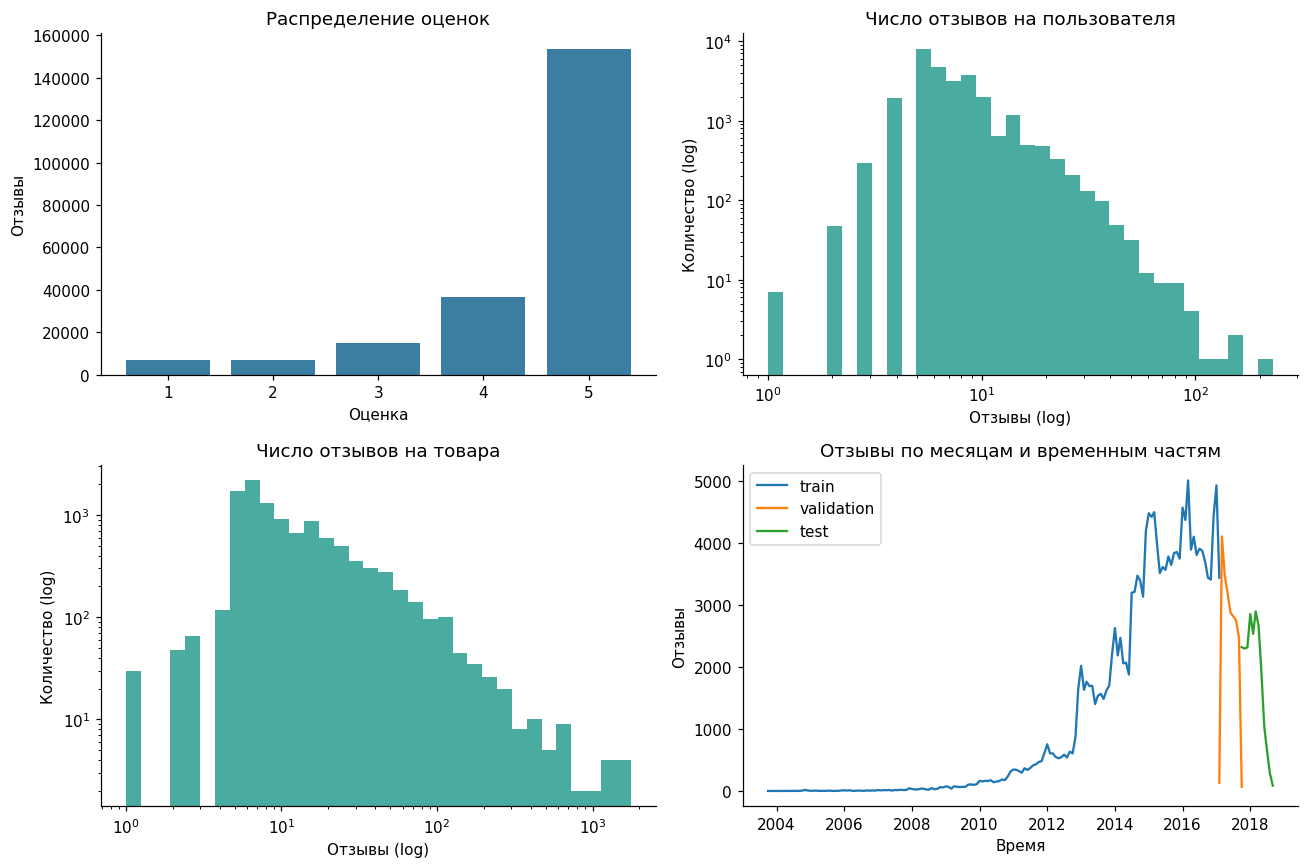

In [15]:
ratings = eda['ratings']
user_activity = eda['user_activity']
item_activity = eda['item_activity']
monthly = eda['monthly']
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0,0].bar(ratings.rating, ratings['count'], color='#3B7EA1')
axes[0,0].set(title='Распределение оценок', xlabel='Оценка', ylabel='Отзывы', xticks=range(1,6))
for frame, ax, name in [(user_activity, axes[0,1], 'пользователя'), (item_activity, axes[1,0], 'товара')]:
    x = frame.interactions.to_numpy()
    bins = np.geomspace(1, max(2, x.max()+1), 35)
    ax.hist(x, bins=bins, color='#2A9D8F', alpha=.85)
    ax.set(xscale='log', yscale='log', title=f'Число отзывов на {name}', xlabel='Отзывы (log)', ylabel='Количество (log)')
for name, group in monthly.groupby('split', sort=False):
    axes[1,1].plot(pd.to_datetime(group.month), group['count'], label=name)
axes[1,1].set(title='Отзывы по месяцам и временным частям', xlabel='Время', ylabel='Отзывы')
axes[1,1].legend()
finish_figure()

In [16]:
top_n = max(1, int(np.ceil(len(item_activity)*0.1)))
top_share = item_activity.interactions.nlargest(top_n).sum()/item_activity.interactions.sum()
display(Markdown(
    f"**Наблюдение.** Медианная история пользователя — **{user_activity.interactions.median():.0f}** отзывов; "
    f"10% самых обсуждаемых товаров собирают **{top_share:.1%}** взаимодействий. "
    "Это обосновывает сравнение с популярностью и отдельную проверку пользователей с короткой историей. "
    "Плотная бинарная матрица здесь в основном заполнена неизвестными парами; трактовать их как достоверный отказ нельзя. "
    "Графики этого раздела описывают весь датасет и не используются для настройки моделей."))

**Наблюдение.** Медианная история пользователя — **6** отзывов; 10% самых обсуждаемых товаров собирают **51.0%** взаимодействий. Это обосновывает сравнение с популярностью и отдельную проверку пользователей с короткой историей. Плотная бинарная матрица здесь в основном заполнена неизвестными парами; трактовать их как достоверный отказ нельзя. Графики этого раздела описывают весь датасет и не используются для настройки моделей.

## 3. Единый временной протокол

Глобальные границы около 80%/90% по времени. Все отзывы одного timestamp попадают в одну часть.
Validation выбирает параметры; перед test модель переобучается на train + validation.
Рекомендация формируется один раз в начале следующего периода по зафиксированной истории,
без обновления после каждого будущего события.
Поскольку время известно только до дня, сутки трактуются как неделимый пакет. Техническое
значение cutoff = max(history.timestamp) + 1 обозначает логическую границу после этого пакета,
а не утверждение, что все отзывы суток были известны в 00:00:01.

**Релевантность:** новый товар с будущей оценкой ≥4. **Кандидаты:** весь каталог товаров,
наблюдавшихся до cutoff; из него удаляются все уже оценённые пользователем товары, включая 1–3 звезды.
Для оценки нужен хотя бы один положительный отзыв в истории и хотя бы один доступный будущий positive.
Новые товары и пользователи не подменяются произвольными fallback-рекомендациями: их доля показана ниже.
Все методы получают один и тот же cohort и кандидатов; sampled negatives на evaluation не используются.
Равные scores разрешаются по возрастанию стабильного item_idx.

Для пользователя $u$ с релевантным множеством $G_u$:
$$
Recall@10_u=\frac{|R_u^{10}\cap G_u|}{|G_u|},\qquad
NDCG@10_u=\frac{\sum_{j=1}^{10}\mathbf{1}[i_j\in G_u]/\log_2(j+1)}{\sum_{j=1}^{\min(10,|G_u|)}1/\log_2(j+1)}.
$$
Метрики усредняются **по пользователям**. Precision делит число попаданий на 10, HitRate — индикатор
хотя бы одного попадания. MAP использует знаменатель min(10, |G_u|). Coverage — доля исторического
каталога, попавшая хотя бы в один top-10.

In [17]:
"""Full-catalog top-k ranking, common eligibility rules and paired uncertainty."""
from __future__ import annotations

from time import perf_counter
import numpy as np
import pandas as pd
from scipy import sparse


def make_evaluation_context(history_df, heldout_df, n_users, n_items):
    """Eligible users have positive history and at least one warm held-out positive.

    Every item observed in history (at any rating) is a candidate; all items
    previously reviewed by a user (including low ratings) are excluded for them.
    Unknown items cannot be predicted by the comparison's collaborative methods.
    """
    candidate_mask = np.zeros(n_items, dtype=bool)
    candidate_mask[history_df.item_idx.to_numpy(dtype=int)] = True
    history_positive = np.bincount(
        history_df.loc[history_df.rating.ge(4), "user_idx"].to_numpy(dtype=int), minlength=n_users
    )
    history_length = np.bincount(history_df.user_idx.to_numpy(dtype=int), minlength=n_users)
    seen = sparse.csr_matrix(
        (np.ones(len(history_df), dtype=np.int8),
         (history_df.user_idx.to_numpy(dtype=int), history_df.item_idx.to_numpy(dtype=int))),
        shape=(n_users, n_items),
    )
    positives = heldout_df.loc[heldout_df.rating.ge(4), ["user_idx", "item_idx"]].drop_duplicates()
    warm_item = candidate_mask[positives.item_idx.to_numpy(dtype=int)]
    warm_user = history_positive[positives.user_idx.to_numpy(dtype=int)] > 0
    previously_seen = np.asarray(seen[positives.user_idx.to_numpy(dtype=int), positives.item_idx.to_numpy(dtype=int)]).ravel() > 0
    eligible_positive = positives.loc[warm_item & warm_user & ~previously_seen]
    targets = {int(u): np.sort(group.item_idx.to_numpy(dtype=int))
               for u, group in eligible_positive.groupby("user_idx", sort=True)}
    users = np.array(sorted(targets), dtype=int)
    raw_positive_users = set(positives.user_idx.tolist())
    warm_positive_users = {u for u in raw_positive_users if history_positive[u] > 0}
    audit = {
        "heldout_interactions": int(len(heldout_df)),
        "heldout_users": int(heldout_df.user_idx.nunique()),
        "heldout_positive_pairs": int(len(positives)),
        "heldout_positive_users": int(len(raw_positive_users)),
        "eligible_users": int(len(users)),
        "excluded_users_without_positive_history": int(len(raw_positive_users - warm_positive_users)),
        "cold_users_with_positives": int(sum(history_length[u] == 0 for u in raw_positive_users)),
        "known_users_without_positive_history": int(sum(history_length[u] > 0 and history_positive[u] == 0 for u in raw_positive_users)),
        "excluded_users_without_available_unseen_positive": int(len(warm_positive_users - set(users))),
        "cold_item_positive_pairs": int((~warm_item).sum()),
        "cold_user_positive_pairs": int((history_length[positives.user_idx.to_numpy(dtype=int)] == 0).sum()),
        "no_positive_history_positive_pairs": int((~warm_user).sum()),
        "previously_seen_positive_pairs": int(previously_seen.sum()),
        "eligible_positive_pairs": int(len(eligible_positive)),
        "eligible_positive_fraction": float(len(eligible_positive) / len(positives)) if len(positives) else 0.0,
        "candidate_items": int(candidate_mask.sum()),
        "cold_catalog_items": int(n_items - candidate_mask.sum()),
        "candidate_policy": "Full historical catalog; mask all previously reviewed items; no sampled negatives.",
    }
    return {"users": users, "targets": targets, "candidate_mask": candidate_mask,
            "seen": seen, "history_length": history_length,
            "positive_history_length": history_positive, "audit": audit}


def deterministic_topk(scores: np.ndarray, k: int) -> np.ndarray:
    """Sort finite candidates by descending score, breaking ties by ascending item index."""
    finite = np.flatnonzero(np.isfinite(scores))
    if len(finite) == 0:
        return np.empty(0, dtype=int)
    count = min(k, len(finite))
    if len(finite) > count:
        values = scores[finite]
        boundary = np.partition(values, len(values) - count)[len(values) - count]
        higher = finite[values > boundary]
        # finite is sorted by item_idx, so deterministic boundary ties need no sort.
        tied = finite[values == boundary][:count - len(higher)]
        selected = np.concatenate([higher, tied])
    else:
        selected = finite
    return selected[np.lexsort((selected, -scores[selected]))]


def user_ranking_metrics(recommended, relevant, k=10):
    hits = np.isin(recommended, relevant).astype(np.float64)
    cumulative = np.cumsum(hits)
    discounts = 1.0 / np.log2(np.arange(2, len(hits) + 2))
    ideal = np.sum(1.0 / np.log2(np.arange(2, min(k, len(relevant)) + 2)))
    return {
        f"NDCG@{k}": float(np.dot(hits, discounts) / ideal) if ideal else 0.0,
        f"Recall@{k}": float(hits.sum() / len(relevant)) if len(relevant) else 0.0,
        f"Precision@{k}": float(hits.sum() / k),
        f"HitRate@{k}": float(hits.sum() > 0),
        f"MAP@{k}": float(np.sum(hits * cumulative / np.arange(1, len(hits) + 1)) / min(k, len(relevant))) if len(relevant) else 0.0,
    }


def evaluate_model(model, history_df, heldout_df, n_users, n_items, k=10, batch_size=128):
    """Return aggregate metrics, one row per eligible user, and ranked recommendations.

    model.score_users(user_indices) must return (batch,n_items) scores. User
    indices and item indices refer to the deterministic dataset-wide mappings.
    No statistic is fitted on heldout_df; it is read only to define relevance.
    """
    if k < 1 or batch_size < 1:
        raise ValueError("k and batch_size must be positive")
    start = perf_counter()
    context = make_evaluation_context(history_df, heldout_df, n_users, n_items)
    if not len(context["users"]):
        raise ValueError("No eligible users under the evaluation protocol")
    per_user, recommendations = [], []
    for offset in range(0, len(context["users"]), batch_size):
        users = context["users"][offset:offset + batch_size]
        scores = np.array(model.score_users(users), dtype=np.float64, copy=True)
        if scores.shape != (len(users), n_items):
            raise ValueError(f"Wrong score shape: {scores.shape}; expected {(len(users), n_items)}")
        if not np.isfinite(scores[:, context["candidate_mask"]]).all():
            raise ValueError("Model returned nonfinite scores for historical candidate items")
        scores[:, ~context["candidate_mask"]] = -np.inf
        for row, user in enumerate(users):
            scores[row, context["seen"].getrow(user).indices] = -np.inf
            topk = deterministic_topk(scores[row], k)
            values = user_ranking_metrics(topk, context["targets"][int(user)], k)
            per_user.append({"user_idx": int(user),
                             "history_length": int(context["history_length"][user]),
                             "positive_history_length": int(context["positive_history_length"][user]),
                             "n_relevant": int(len(context["targets"][int(user)])),
                             "n_recommendations": int(len(topk)), **values})
            recommendations.extend({"user_idx": int(user), "rank": rank,
                                    "item_idx": int(item), "score": float(scores[row, item])}
                                   for rank, item in enumerate(topk, start=1))
    per_user = pd.DataFrame(per_user)
    topk_df = pd.DataFrame(recommendations, columns=["user_idx", "rank", "item_idx", "score"])
    metric_names = [f"{name}@{k}" for name in ["NDCG", "Recall", "Precision", "HitRate", "MAP"]]
    metrics = {name: float(per_user[name].mean()) for name in metric_names}
    metrics[f"Coverage@{k}"] = float(topk_df.item_idx.nunique() / context["candidate_mask"].sum())
    metrics["n_evaluated_users"] = int(len(per_user))
    metrics["evaluation_seconds"] = float(perf_counter() - start)
    metrics["evaluation"] = context["audit"]
    return metrics, per_user, topk_df


def paired_bootstrap(base_df, custom_df, metric="NDCG@10", n_bootstrap=2000, seed=42, confidence=0.95):
    """Percentile bootstrap CI of mean(custom-base), resampling paired users.

    This quantifies user-sampling uncertainty for the fixed trained models,
    not retraining uncertainty or temporal generalization to another period.
    """
    if not 0 < confidence < 1 or n_bootstrap < 1:
        raise ValueError("Invalid bootstrap configuration")
    if base_df.user_idx.duplicated().any() or custom_df.user_idx.duplicated().any():
        raise ValueError("Each input must contain exactly one row per user")
    if set(base_df.user_idx) != set(custom_df.user_idx):
        raise ValueError("Paired models must be evaluated on identical users")
    joined = base_df[["user_idx", metric]].merge(custom_df[["user_idx", metric]], on="user_idx", suffixes=("_base", "_custom"), validate="one_to_one").sort_values("user_idx")
    if joined.empty:
        raise ValueError("No paired users")
    differences = (joined[metric + "_custom"] - joined[metric + "_base"]).to_numpy()
    rng = np.random.default_rng(seed)
    means = np.empty(n_bootstrap)
    for offset in range(0, n_bootstrap, 100):
        count = min(100, n_bootstrap - offset)
        sampled = rng.integers(0, len(differences), size=(count, len(differences)))
        means[offset:offset + count] = differences[sampled].mean(axis=1)
    alpha = (1.0 - confidence) / 2
    return {"metric": metric, "mean_difference": float(differences.mean()),
            "ci_lower": float(np.quantile(means, alpha)), "ci_upper": float(np.quantile(means, 1 - alpha)),
            "confidence": confidence, "n_users": int(len(differences)),
            "n_bootstrap": n_bootstrap, "seed": seed,
            "direction": "custom_minus_base", "resampling_unit": "user"}

In [18]:
display(eda['splits'])
history = pd.concat([data['train'], data['validation']], ignore_index=True)
validation_audit = make_evaluation_context(
    data['train'], data['validation'], data['n_users'], data['n_items'])['audit']
test_audit = make_evaluation_context(
    history, data['test'], data['n_users'], data['n_items'])['audit']
audit_names = ['heldout_interactions','heldout_positive_pairs','heldout_positive_users','eligible_users',
               'candidate_items','cold_item_positive_pairs','excluded_users_without_positive_history',
               'eligible_positive_pairs','eligible_positive_fraction']
display(pd.DataFrame({'validation':validation_audit,'test':test_audit}).loc[audit_names])
display(Markdown(f"**Область применимости.** В test остаётся {test_audit['eligible_users']:,} пользователей "
                 f"и {test_audit['eligible_positive_fraction']:.1%} положительных пар. "
                 "Это качество warm-start discovery, а не качество на всех будущих клиентах и товарах."))

,split,events,users,items,positive_share,start,end
0,train,175360,25436,10521,0.868813,2003-10-28T00:00:00+00:00,2017-02-27T00:00:00+00:00
1,validation,21904,7531,6109,0.868700,2017-02-28T00:00:00+00:00,2017-10-01T00:00:00+00:00
2,test,21892,7253,5874,0.852366,2017-10-02T00:00:00+00:00,2018-09-28T00:00:00+00:00


,validation,test
heldout_interactions,21904,21892
heldout_positive_pairs,19028,18660
heldout_positive_users,6890,6591
eligible_users,5512,5631
candidate_items,10521,10599
cold_item_positive_pairs,198,88
excluded_users_without_positive_history,1335,945
eligible_positive_pairs,12822,13267
eligible_positive_fraction,0.673849,0.710986


**Область применимости.** В test остаётся 5,631 пользователей и 71.1% положительных пар. Это качество warm-start discovery, а не качество на всех будущих клиентах и товарах.

## 4. Пять моделей: постановка и собственная реализация

Обозначим $R_{ui}=\mathbf{1}[r_{ui}\ge4]$, $O_{ui}=\mathbf{1}[(u,i)\text{ наблюдалась}]$.
Неизвестные пары в $R$ равны нулю, но это не делает их достоверными отрицательными отзывами.

### 4.1. ItemKNN
$$
s_{ij}=\frac{R_{:i}^{\top}R_{:j}}{\|R_{:i}\|_2\|R_{:j}\|_2}
\cdot\frac{n_{ij}}{n_{ij}+\beta},\quad s_{ii}=0,
\qquad \hat y_{ui}=\sum_{j\in I_u^+\cap N_K(i)}s_{ji}.
$$
$n_{ij}$ — число общих положительных пользователей. Shrinkage уменьшает влияние совпадений
на малом числе наблюдений. Разреженные пересечения и top-K соседей реализованы в следующей ячейке.



In [19]:
"""Item-neighbour recommendations implemented with sparse matrix algebra."""

import time

import numpy as np
from scipy import sparse


class ItemKNN:
    """Binary positive-history cosine similarity with overlap shrinkage.

    Each candidate item selects its ``top_k`` historical-item neighbours.
    ``W_[source, candidate]`` therefore gives the source's contribution to a
    candidate score, and recommendations are scored as ``X_ @ W_``.
    Previously seen items are masked by the shared evaluation code.
    """

    def __init__(self, top_k=100, shrinkage=10.0, positive_threshold=4.0):
        if int(top_k) != top_k or top_k < 1:
            raise ValueError("top_k must be a positive integer")
        if not np.isfinite(shrinkage) or shrinkage < 0:
            raise ValueError("shrinkage must be finite and nonnegative")
        self.top_k = int(top_k)
        self.shrinkage = float(shrinkage)
        self.positive_threshold = float(positive_threshold)

    def fit(self, history_df, n_users, n_items, cutoff=None):
        started = time.perf_counter()
        self.n_users_, self.n_items_ = int(n_users), int(n_items)
        positive = history_df.loc[history_df.rating >= self.positive_threshold]
        self.X_ = sparse.csr_matrix(
            (np.ones(len(positive), dtype=np.float32),
             (positive.user_idx.to_numpy(), positive.item_idx.to_numpy())),
            shape=(self.n_users_, self.n_items_), dtype=np.float32,
        )
        self.X_.sum_duplicates()
        self.X_.data.fill(1.0)
        counts = np.asarray(self.X_.sum(axis=0)).ravel()
        cooccurrence = (self.X_.T @ self.X_).tocsr()
        cooccurrence.setdiag(0)
        cooccurrence.eliminate_zeros()
        # The symmetric co-occurrence row is interpreted as a candidate's
        # possible source neighbours. Transpose once after top-k selection.
        out_indices, out_data = [], []
        out_indptr = [0]
        for candidate in range(self.n_items_):
            begin, end = cooccurrence.indptr[candidate:candidate + 2]
            sources = cooccurrence.indices[begin:end]
            overlap = cooccurrence.data[begin:end]
            similarities = overlap / np.sqrt(counts[candidate] * counts[sources])
            if self.shrinkage:
                similarities *= overlap / (overlap + self.shrinkage)
            # Secondary key makes ties independent of sparse storage order.
            chosen = np.lexsort((sources, -similarities))[:self.top_k]
            out_indices.extend(sources[chosen].tolist())
            out_data.extend(similarities[chosen].tolist())
            out_indptr.append(len(out_indices))
        target_source = sparse.csr_matrix(
            (np.asarray(out_data, dtype=np.float32),
             np.asarray(out_indices, dtype=np.int32),
             np.asarray(out_indptr, dtype=np.int64)),
            shape=(self.n_items_, self.n_items_),
        )
        self.W_ = target_source.T.tocsr()
        self.history_ = [{"fit_seconds": time.perf_counter() - started,
                          "positive_pairs": int(self.X_.nnz),
                          "similarity_edges": int(self.W_.nnz)}]
        return self

    def score_users(self, user_ids):
        if not hasattr(self, "W_"):
            raise RuntimeError("Call fit before scoring")
        users = np.asarray(user_ids, dtype=np.int64)
        return (self.X_[users] @ self.W_).toarray()

### 4.2. Базовый iALS
$$
p_{ui}=R_{ui},\quad c_{ui}=1+\alpha O_{ui},\qquad
L=\sum_{u,i}c_{ui}(p_{ui}-x_u^\top y_i)^2+\lambda(\|X\|_F^2+\|Y\|_F^2).
$$
Наблюдавшаяся низкая оценка имеет target=0 и высокий confidence; неизвестная пара — target=0
и confidence=1. При фиксированном $Y$:
$$
x_u=(Y^\top C_uY+\lambda I)^{-1}Y^\top C_up_u.
$$
В коде решается линейная система, явная обратная матрица не строится. Обновления товаров симметричны.
Полный декартов продукт не материализуется: используется общий Gram и поправка по наблюдавшимся парам.
Постановка следует [Hu, Koren, Volinsky (2008)](https://yifanhu.net/PUB/cf.pdf).



In [20]:
"""Confidence-weighted ALS with independently defined preference targets.

Both variants minimize the objective over *all* user/item pairs. An observed
rating, including a neutral or negative rating, has confidence ``1 + alpha``;
a missing pair has confidence one and target zero. Explicit zeros in the
sparse target matrix are observations and must never be eliminated.
"""

import time

import numpy as np
import pandas as pd
from scipy import sparse
from scipy.linalg import solve


def _timestamp_seconds(values):
    """Accept Unix-second numbers or datetime-like values without unit guessing."""
    if pd.api.types.is_numeric_dtype(values.dtype):
        result = np.asarray(values, dtype=np.float64)
    else:
        parsed = pd.to_datetime(values, utc=True, errors="raise")
        if parsed.isna().any():
            raise ValueError("timestamps must not contain missing values")
        result = np.asarray(parsed.astype("int64"), dtype=np.float64) / 1e9
    if not np.isfinite(result).all():
        raise ValueError("timestamps must be finite")
    return result


def _cutoff_seconds(value):
    if isinstance(value, (int, float, np.integer, np.floating)):
        result = float(value)
    else:
        result = pd.Timestamp(value).timestamp()
    if not np.isfinite(result):
        raise ValueError("cutoff must be finite")
    return result


def _als_half_step(fixed_factors, observations, alpha, reg):
    """Solve one exact ALS half-step using a cached Gram matrix.

    ``observations`` is CSR: its stored entries include target-zero and
    negative observations. This function is also used in dense-reference
    tests of the weighted all-pairs objective.
    """
    observations = observations.tocsr(copy=False)
    fixed_factors = np.asarray(fixed_factors, dtype=np.float64)
    factors = fixed_factors.shape[1]
    gram = fixed_factors.T @ fixed_factors
    gram.flat[::factors + 1] += reg
    updated = np.zeros((observations.shape[0], factors), dtype=np.float64)
    confidence = 1.0 + alpha
    for row in range(observations.shape[0]):
        begin, end = observations.indptr[row:row + 2]
        if begin == end:
            continue
        indices = observations.indices[begin:end]
        targets = observations.data[begin:end]
        selected = fixed_factors[indices]
        normal = gram + alpha * (selected.T @ selected)
        rhs = confidence * (selected.T @ targets)
        updated[row] = solve(normal, rhs, assume_a="pos", check_finite=False,
                             overwrite_a=True, overwrite_b=True)
    return updated


class ImplicitALS:
    """All-pairs iALS with target one for ratings >= 4, otherwise zero."""

    def __init__(self, n_factors=32, reg=0.1, alpha=20.0, n_iters=8,
                 seed=42, positive_threshold=4.0):
        if int(n_factors) != n_factors or n_factors < 1:
            raise ValueError("n_factors must be a positive integer")
        if int(n_iters) != n_iters or n_iters < 1:
            raise ValueError("n_iters must be a positive integer")
        if not np.isfinite(reg) or reg <= 0:
            raise ValueError("reg must be finite and positive")
        if not np.isfinite(alpha) or alpha < 0:
            raise ValueError("alpha must be finite and nonnegative")
        self.n_factors = int(n_factors)
        self.reg, self.alpha = float(reg), float(alpha)
        self.n_iters, self.seed = int(n_iters), int(seed)
        self.positive_threshold = float(positive_threshold)

    def _targets(self, history_df, cutoff):
        return (history_df.rating.to_numpy() >= self.positive_threshold).astype(np.float64)

    def fit(self, history_df, n_users, n_items, cutoff=None):
        """Fit on unique observed pairs; ``cutoff`` is the recommendation time.

        Timestamps, when numeric, are Unix seconds. Duplicate user/item pairs
        must be resolved by the common preprocessing, rather than differently
        inside each model. The baseline accepts cutoff for interface parity.
        """
        self.n_users_, self.n_items_ = int(n_users), int(n_items)
        if self.n_users_ < 1 or self.n_items_ < 1:
            raise ValueError("n_users and n_items must be positive")
        if history_df.duplicated(["user_idx", "item_idx"]).any():
            raise ValueError("Resolve duplicate user/item pairs before fitting")
        ratings = history_df.rating.to_numpy(dtype=np.float64)
        if not np.isfinite(ratings).all() or ((ratings < 1) | (ratings > 5)).any():
            raise ValueError("ratings must be finite values in [1, 5]")
        targets = self._targets(history_df, cutoff)
        self.observations_ = sparse.csr_matrix(
            (targets, (history_df.user_idx.to_numpy(), history_df.item_idx.to_numpy())),
            shape=(self.n_users_, self.n_items_), dtype=np.float64,
        )
        self.observations_.sort_indices()
        # Keep explicit zero targets: their confidence still exceeds one.
        item_observations = self.observations_.T.tocsr()
        rng = np.random.default_rng(self.seed)
        self.user_factors_ = rng.normal(0.0, 0.01, (self.n_users_, self.n_factors))
        self.item_factors_ = rng.normal(0.0, 0.01, (self.n_items_, self.n_factors))
        self.history_ = [{"iteration": 0, "objective": self.objective(),
                          "iteration_seconds": 0.0}]
        for iteration in range(1, self.n_iters + 1):
            started = time.perf_counter()
            self.user_factors_ = _als_half_step(
                self.item_factors_, self.observations_, self.alpha, self.reg)
            self.item_factors_ = _als_half_step(
                self.user_factors_, item_observations, self.alpha, self.reg)
            self.history_.append({"iteration": iteration, "objective": self.objective(),
                                  "iteration_seconds": time.perf_counter() - started})
        return self

    def objective(self):
        """Exact training loss without constructing a dense user/item matrix."""
        user, item = self.user_factors_, self.item_factors_
        user_gram, item_gram = user.T @ user, item.T @ item
        loss = float(np.sum(user_gram * item_gram))
        observations = self.observations_.tocoo(copy=False)
        for begin in range(0, observations.nnz, 8192):
            end = min(begin + 8192, observations.nnz)
            scores = np.einsum("ij,ij->i", user[observations.row[begin:end]],
                               item[observations.col[begin:end]])
            residual = observations.data[begin:end] - scores
            loss += float(np.sum((1.0 + self.alpha) * residual ** 2 - scores ** 2))
        loss += self.reg * (float(np.sum(user ** 2)) + float(np.sum(item ** 2)))
        return loss

    def score_users(self, user_ids):
        if not hasattr(self, "item_factors_"):
            raise RuntimeError("Call fit before scoring")
        return self.user_factors_[np.asarray(user_ids, dtype=np.int64)] @ self.item_factors_.T


class CustomTargetALS(ImplicitALS):
    """Signed satisfaction with a half-life, keeping baseline confidence fixed.

    q_ui(T) = ((rating_ui - 3) / 2) * 2 ** (-(T - timestamp_ui) / H).
    ``half_life_days=None`` disables decay for the rating-only ablation.
    """

    def __init__(self, n_factors=32, reg=0.1, alpha=20.0, n_iters=8,
                 seed=42, half_life_days=730.0):
        super().__init__(n_factors=n_factors, reg=reg, alpha=alpha,
                         n_iters=n_iters, seed=seed)
        if half_life_days is not None and (
                not np.isfinite(half_life_days) or half_life_days <= 0):
            raise ValueError("half_life_days must be positive or None")
        self.half_life_days = half_life_days

    def _targets(self, history_df, cutoff):
        timestamps = _timestamp_seconds(history_df.timestamp)
        if cutoff is None:
            self.cutoff_ = float(timestamps.max()) if len(timestamps) else 0.0
        else:
            self.cutoff_ = _cutoff_seconds(cutoff)
        if len(timestamps) and (timestamps > self.cutoff_).any():
            raise ValueError("training observations must not follow the cutoff")
        targets = (history_df.rating.to_numpy(dtype=np.float64) - 3.0) / 2.0
        if self.half_life_days is not None:
            age_days = (self.cutoff_ - timestamps) / 86400.0
            targets *= np.exp2(-age_days / self.half_life_days)
        return targets

### 4.3. EASE
$$
\min_B\|R-RB\|_F^2+\lambda\|B\|_F^2,\quad\operatorname{diag}(B)=0.
\quad P=(R^\top R+\lambda I)^{-1},\quad B_{ij}=-P_{ij}/P_{jj}\;(i\ne j).
$$
Предсказания — $RB$. Нулевая диагональ не позволяет копировать собственную оценку.
В следующей ячейке используются численные примитивы Cholesky/LAPACK; это собственная реализация
[EASE, Steck (2019)](https://arxiv.org/abs/1905.03375), а не готовый обучаемый алгоритм.
Плотная item×item матрица делает EASE наиболее требовательным к памяти методом этого сравнения.

In [21]:
"""EASE closed-form item reconstruction with an in-place Cholesky inverse."""

import time

import numpy as np
from scipy import sparse
from scipy.linalg.lapack import dpotrf, dpotri


class EASE:
    """Minimize ||X-XB||_F^2 + reg*||B||_F^2 with diag(B)=0.

    If P = (X.T@X + reg*I)^(-1), B_ij = -P_ij/P_jj for i != j.
    The dense float64 Gram matrix is overwritten by its Cholesky factor and
    inverse. Only the final scoring weights are stored as float32.
    """

    def __init__(self, reg=100.0, positive_threshold=4.0):
        if not np.isfinite(reg) or reg <= 0:
            raise ValueError("reg must be finite and positive")
        self.reg = float(reg)
        self.positive_threshold = float(positive_threshold)

    def fit(self, history_df, n_users, n_items, cutoff=None):
        started = time.perf_counter()
        self.n_users_, self.n_items_ = int(n_users), int(n_items)
        if self.n_users_ < 1 or self.n_items_ < 1:
            raise ValueError("n_users and n_items must be positive")
        positive = history_df.loc[history_df.rating >= self.positive_threshold]
        self.X_ = sparse.csr_matrix(
            (np.ones(len(positive), dtype=np.float32),
             (positive.user_idx.to_numpy(), positive.item_idx.to_numpy())),
            shape=(self.n_users_, self.n_items_), dtype=np.float32,
        )
        self.X_.sum_duplicates()
        self.X_.data.fill(1.0)
        history64 = self.X_.astype(np.float64)
        sparse_gram = (history64.T @ history64).tocsc()
        gram = sparse_gram.toarray(order="F")
        del sparse_gram, history64
        gram.flat[::self.n_items_ + 1] += self.reg
        factor, info = dpotrf(gram, lower=1, overwrite_a=1, clean=0)
        if info != 0:
            raise np.linalg.LinAlgError("EASE Cholesky factorization failed: %d" % info)
        del gram
        precision, info = dpotri(factor, lower=1, overwrite_c=1)
        if info != 0:
            raise np.linalg.LinAlgError("EASE Cholesky inversion failed: %d" % info)
        del factor
        # LAPACK returns the lower triangle. Mirror in place instead of
        # allocating a second dense matrix or an O(n_items^2) index array.
        for column in range(self.n_items_):
            precision[:column, column] = precision[column, :column]
        diagonal = precision.diagonal().copy()
        if not np.isfinite(diagonal).all() or (diagonal <= 0).any():
            raise np.linalg.LinAlgError("EASE inverse has an invalid diagonal")
        precision /= -diagonal[np.newaxis, :]
        np.fill_diagonal(precision, 0.0)
        self.W_ = precision.astype(np.float32)
        self.history_ = [{"fit_seconds": time.perf_counter() - started,
                          "positive_pairs": int(self.X_.nnz),
                          "dense_float64_bytes": int(8 * self.n_items_ ** 2),
                          "weights_float32_bytes": int(self.W_.nbytes)}]
        return self

    def score_users(self, user_ids):
        if not hasattr(self, "W_"):
            raise RuntimeError("Call fit before scoring")
        return np.asarray(self.X_[np.asarray(user_ids, dtype=np.int64)] @ self.W_)

### 4.4. Factorization Machine с метапризнаками
$$
f(z)=w_0+\sum_jw_jz_j+\sum_{j<k}\langle v_j,v_k\rangle z_jz_k,
\quad L=\operatorname{BCE}(f(z),y)+\frac{\lambda}{2}\|\theta\|_2^2.
$$
Помимо user/item ID используются восемь числовых признаков: исторические count, mean rating и доля
положительных оценок для пользователя и товара; sin/cos годового календарного цикла.
Активность помогает оценить надёжность истории, средние оценки — различия в строгости пользователей
и удовлетворённости товарами, календарь — возможную сезонность. Это проверяемые предположения, не обещание выигрыша.

`count` преобразуется как log(1+count)/log(1001), средняя оценка делится на 5; масштабы фиксированы заранее.
Пустая история получает mean=3 и positive share=0.5. Все агрегаты рассчитываются по событиям **строго раньше**
timestamp обучающего примера; события с одинаковым временем друг друга не видят. При рекомендации используется
snapshot до cutoff. Снимки карточек Amazon не имеют полной временной истории, поэтому категории, бренд и
название здесь не являются признаками обучения. Текст будущего отзыва тоже не используется.

Наблюдаемые отзывы дают label=1 для 4–5 и label=0 для 1–3. На каждый положительный отзыв добавляется
до двух ненаблюдавшихся пар из каталога, уже существовавшего к его времени. Прошлые товары пользователя
исключаются, будущие positives специально не подсматриваются. Это sampled-negative surrogate,
его logit не является откалиброванной вероятностью покупки.

Обучение — PyTorch/autograd/Adam; взаимодействия реализованы собственной формулой в ячейка FM ниже.
L2 применяется ко всем параметрам, кроме свободного члена $w_0$; sampler исключает также
товары из одновременных отзывов пользователя, порядок которых неизвестен.
При scoring признаки разделены на группы user/item, поэтому все cross-взаимодействия считаются точным
матричным произведением. Код не перебирает Python-циклом миллионы пар.
Основная формула: [Rendle (2010), Factorization Machines](https://doi.org/10.1109/ICDM.2010.127).

In [22]:
"""Causal user/item metadata and availability-aware negative sampling.

No statistic includes events at the query timestamp. This also makes equal-time
reviews independent of their row order. Scaling constants are fixed a priori,
so training-period future rows cannot change earlier transformed features.
"""
from typing import Tuple

import numpy as np
import pandas as pd


USER_FEATURE_NAMES = (
    "log_user_count", "user_mean_rating", "user_positive_share",
    "calendar_sin", "calendar_cos",
)
ITEM_FEATURE_NAMES = (
    "log_item_count", "item_mean_rating", "item_positive_share",
)


class _EntityHistory:
    """Vectorized as-of lookups using packed, sorted (entity, timestamp) keys."""

    def __init__(self, ids, timestamps, ratings, n_entities):
        ids = np.asarray(ids, dtype=np.int64)
        timestamps = np.asarray(timestamps, dtype=np.int64)
        ratings = np.asarray(ratings, dtype=np.float64)
        self.n_entities = int(n_entities)
        self.min_time = int(timestamps.min())
        self.max_time = int(timestamps.max())
        self.stride = self.max_time - self.min_time + 3
        if self.stride * max(n_entities, 1) >= np.iinfo(np.int64).max:
            raise ValueError("Entity/timestamp range exceeds the packed-key limit")
        order = np.lexsort((timestamps, ids))
        sorted_ids, sorted_times = ids[order], timestamps[order]
        sorted_ratings = ratings[order]
        self.ids = sorted_ids
        self.keys = self._keys(sorted_ids, sorted_times)
        starts = np.r_[0, np.flatnonzero(np.diff(sorted_ids)) + 1]
        group_number = np.cumsum(np.r_[True, np.diff(sorted_ids) != 0]) - 1
        counts = np.arange(1, len(ids) + 1, dtype=np.int64)
        rating_sum = np.cumsum(sorted_ratings)
        positive_sum = np.cumsum(sorted_ratings >= 4, dtype=np.int64)
        self.counts = counts - starts[group_number]
        self.rating_sums = rating_sum - np.r_[0.0, rating_sum[starts[1:] - 1]][group_number]
        self.positive_sums = positive_sum - np.r_[0, positive_sum[starts[1:] - 1]][group_number]

    def _keys(self, ids, timestamps):
        offsets = np.clip(np.asarray(timestamps, dtype=np.int64) - self.min_time + 1,
                          0, self.stride - 1)
        return np.asarray(ids, dtype=np.int64) * self.stride + offsets

    def query(self, ids, timestamps):
        ids, timestamps = np.broadcast_arrays(np.asarray(ids, dtype=np.int64),
                                              np.asarray(timestamps, dtype=np.int64))
        if np.any(ids < 0) or np.any(ids >= self.n_entities):
            raise ValueError("Entity ID outside the fitted vocabulary")
        indices = np.searchsorted(self.keys, self._keys(ids, timestamps), side="left") - 1
        safe_indices = np.maximum(indices, 0)
        present = (indices >= 0) & (self.ids[safe_indices] == ids)
        count = np.where(present, self.counts[safe_indices], 0)
        rating_sum = np.where(present, self.rating_sums[safe_indices], 0.0)
        positive_sum = np.where(present, self.positive_sums[safe_indices], 0.0)
        mean = np.divide(rating_sum, count, out=np.full(ids.shape, 3.0), where=count > 0)
        positive_share = np.divide(positive_sum, count, out=np.full(ids.shape, 0.5),
                                   where=count > 0)
        return count, mean, positive_share


class CausalFeatureStore:
    """Metadata available strictly before each query's Unix-second timestamp.

    User and item groups are disjoint, permitting exact matrix-multiply FM
    inference. Means/shares use fixed cold-start defaults of 3 stars and 0.5.
    ``log1p(count) / log(1001)`` has a fixed scale, not a fitted full-data scale.
    Calendar features are sine/cosine of Unix time with a 365.2425-day period.
    """

    user_feature_names = USER_FEATURE_NAMES
    item_feature_names = ITEM_FEATURE_NAMES

    def __init__(self, history: pd.DataFrame, n_users: int, n_items: int):
        if history.empty:
            raise ValueError("History must contain at least one interaction")
        self.n_users, self.n_items = int(n_users), int(n_items)
        times = history["timestamp"].to_numpy(dtype=np.int64)
        ratings = history["rating"].to_numpy(dtype=np.float64)
        self.min_time, self.max_time = int(times.min()), int(times.max())
        self.user_history = _EntityHistory(history["user_idx"].to_numpy(), times,
                                           ratings, n_users)
        self.item_history = _EntityHistory(history["item_idx"].to_numpy(), times,
                                           ratings, n_items)

    @staticmethod
    def _numeric_features(count, mean, positive_share):
        return np.stack((np.log1p(count) / np.log(1001.0), mean / 5.0,
                         positive_share), axis=-1).astype(np.float32)

    def user_features(self, users, timestamps):
        users, timestamps = np.broadcast_arrays(np.asarray(users, dtype=np.int64),
                                                np.asarray(timestamps, dtype=np.int64))
        basic = self._numeric_features(*self.user_history.query(users, timestamps))
        phase = 2.0 * np.pi * timestamps / (365.2425 * 86400.0)
        return np.concatenate((basic, np.stack((np.sin(phase), np.cos(phase)), axis=-1)),
                              axis=-1).astype(np.float32)

    def item_features(self, items, timestamps):
        return self._numeric_features(*self.item_history.query(items, timestamps))

    def pair_features(self, users, items, timestamps) -> Tuple[np.ndarray, np.ndarray]:
        return self.user_features(users, timestamps), self.item_features(items, timestamps)

    def snapshot(self, cutoff: int) -> Tuple[np.ndarray, np.ndarray]:
        return (self.user_features(np.arange(self.n_users), cutoff),
                self.item_features(np.arange(self.n_items), cutoff))


def sample_training_pairs(history: pd.DataFrame, n_items: int, negative_ratio: int = 2,
                          seed: int = 42):
    """Observed binary targets plus causal sampled negatives for positive events.

    The catalog contains items whose first observed review is strictly before the
    event. A user's already reviewed items (including simultaneous reviews) are
    excluded. Future positive events are deliberately *not* consulted. Rejection
    sampling is vectorized; unresolved draws after 100 attempts are discarded,
    which matters only for tiny early-time catalogs with no valid alternatives.
    """
    if negative_ratio < 0:
        raise ValueError("negative_ratio must be nonnegative")
    users = history["user_idx"].to_numpy(dtype=np.int64)
    items = history["item_idx"].to_numpy(dtype=np.int64)
    times = history["timestamp"].to_numpy(dtype=np.int64)
    labels = (history["rating"].to_numpy() >= 4).astype(np.float32)
    positive_indices = np.repeat(np.flatnonzero(labels > 0), negative_ratio)
    if not len(positive_indices):
        return users, items, times, labels
    item_first = history.groupby("item_idx", sort=False)["timestamp"].min()
    order = np.lexsort((item_first.index.to_numpy(), item_first.to_numpy()))
    available_items = item_first.index.to_numpy(dtype=np.int64)[order]
    available_times = item_first.to_numpy(dtype=np.int64)[order]
    pair_ids = users * n_items + items
    pair_order = np.lexsort((times, pair_ids))
    sorted_pairs, sorted_times = pair_ids[pair_order], times[pair_order]
    first = np.r_[True, sorted_pairs[1:] != sorted_pairs[:-1]]
    unique_pairs, first_pair_times = sorted_pairs[first], sorted_times[first]
    neg_users, neg_times = users[positive_indices], times[positive_indices]
    catalog_sizes = np.searchsorted(available_times, neg_times, side="left")
    neg_items = np.full(len(positive_indices), -1, dtype=np.int64)
    pending = np.flatnonzero(catalog_sizes > 0)
    rng = np.random.default_rng(seed)
    for _ in range(100):
        if not len(pending):
            break
        candidates = available_items[rng.integers(0, catalog_sizes[pending])]
        candidate_pairs = neg_users[pending] * n_items + candidates
        positions = np.searchsorted(unique_pairs, candidate_pairs)
        safe_positions = np.minimum(positions, len(unique_pairs) - 1)
        seen = ((positions < len(unique_pairs))
                & (unique_pairs[safe_positions] == candidate_pairs)
                & (first_pair_times[safe_positions] <= neg_times[pending]))
        accepted = pending[~seen]
        neg_items[accepted] = candidates[~seen]
        pending = pending[seen]
    accepted = neg_items >= 0
    return (np.r_[users, neg_users[accepted]], np.r_[items, neg_items[accepted]],
            np.r_[times, neg_times[accepted]],
            np.r_[labels, np.zeros(accepted.sum(), dtype=np.float32)])

In [23]:
"""A second-order factorization machine implemented with PyTorch primitives."""
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F



class _FMModule(nn.Module):
    """ID fields and real-valued metadata fields, with the standard FM identity."""

    def __init__(self, n_users, n_items, n_factors, n_user_features, n_item_features):
        super().__init__()
        self.bias = nn.Parameter(torch.zeros(()))
        self.user_linear = nn.Embedding(n_users, 1)
        self.item_linear = nn.Embedding(n_items, 1)
        self.user_factors = nn.Embedding(n_users, n_factors)
        self.item_factors = nn.Embedding(n_items, n_factors)
        self.user_numeric_linear = nn.Parameter(torch.zeros(n_user_features))
        self.item_numeric_linear = nn.Parameter(torch.zeros(n_item_features))
        self.user_numeric_factors = nn.Parameter(torch.empty(n_user_features, n_factors))
        self.item_numeric_factors = nn.Parameter(torch.empty(n_item_features, n_factors))
        nn.init.zeros_(self.user_linear.weight)
        nn.init.zeros_(self.item_linear.weight)
        for parameter in (self.user_factors.weight, self.item_factors.weight,
                          self.user_numeric_factors, self.item_numeric_factors):
            nn.init.normal_(parameter, mean=0.0, std=0.05)

    @staticmethod
    def group_components(ids, numeric, id_linear, id_factors,
                         numeric_linear, numeric_factors):
        factors = id_factors(ids)
        factor_sum = factors + numeric @ numeric_factors
        factor_square_sum = factors.square() + numeric.square() @ numeric_factors.square()
        linear = id_linear(ids).squeeze(-1) + numeric @ numeric_linear
        within = 0.5 * (factor_sum.square() - factor_square_sum).sum(dim=-1)
        return linear + within, factor_sum

    def user_components(self, users, numeric):
        return self.group_components(users, numeric, self.user_linear, self.user_factors,
                                     self.user_numeric_linear, self.user_numeric_factors)

    def item_components(self, items, numeric):
        return self.group_components(items, numeric, self.item_linear, self.item_factors,
                                     self.item_numeric_linear, self.item_numeric_factors)

    def forward(self, users, items, user_numeric, item_numeric):
        user_base, user_factors = self.user_components(users, user_numeric)
        item_base, item_factors = self.item_components(items, item_numeric)
        return self.bias + user_base + item_base + (user_factors * item_factors).sum(dim=-1)


class FactorizationMachine:
    """FM optimized with sampled binary cross-entropy and explicit L2 decay.

    ID one-hot vectors are implemented as embedding lookups. Historical metadata
    is computed before each training event; metadata at inference uses the frozen
    training cutoff. ``with_metadata=False`` is the ID-only ablation, with exactly
    the same labels and negative-sampling procedure. Scores are raw logits.

    The split user/item factorization makes full-catalog scores exact without
    explicitly constructing features for every user-item pair.
    """

    def __init__(self, n_factors=16, epochs=6, batch_size=2048, negative_ratio=2,
                 learning_rate=0.01, regularization=1e-5, seed=42,
                 with_metadata=True, n_threads=2):
        self.n_factors = int(n_factors)
        self.epochs = int(epochs)
        self.batch_size = int(batch_size)
        self.negative_ratio = int(negative_ratio)
        self.learning_rate = float(learning_rate)
        self.regularization = float(regularization)
        self.seed = int(seed)
        self.with_metadata = bool(with_metadata)
        self.n_threads = int(n_threads)

    def fit(self, history_df, n_users, n_items, cutoff=None):
        self.n_users_, self.n_items_ = int(n_users), int(n_items)
        self.features_ = CausalFeatureStore(history_df, n_users, n_items)
        self.cutoff_ = int(cutoff if cutoff is not None else self.features_.max_time + 1)
        if self.cutoff_ <= self.features_.max_time:
            raise ValueError("cutoff must be strictly later than all training timestamps")
        torch.set_num_threads(self.n_threads)
        torch.manual_seed(self.seed)
        users, items, times, targets = sample_training_pairs(
            history_df, n_items, self.negative_ratio, self.seed)
        if self.with_metadata:
            user_numeric, item_numeric = self.features_.pair_features(users, items, times)
        else:
            user_numeric = np.empty((len(users), 0), dtype=np.float32)
            item_numeric = np.empty((len(items), 0), dtype=np.float32)
        self.n_training_pairs_ = len(users)
        self.n_sampled_negatives_ = len(users) - len(history_df)
        self.model_ = _FMModule(n_users, n_items, self.n_factors,
                                user_numeric.shape[1], item_numeric.shape[1])
        tensors = [torch.from_numpy(a) for a in (users, items, user_numeric, item_numeric, targets)]
        # Adam's coupled weight_decay adds lambda*theta to the gradient, matching
        # BCE + (lambda/2)||theta||^2. The intercept is left unregularized.
        parameters = [p for name, p in self.model_.named_parameters() if name != "bias"]
        optimizer = torch.optim.Adam([
            {"params": parameters, "weight_decay": self.regularization},
            {"params": [self.model_.bias], "weight_decay": 0.0},
        ], lr=self.learning_rate)
        rng = np.random.default_rng(self.seed + 1)
        self.history_ = []
        self.model_.train()
        for epoch in range(self.epochs):
            order = rng.permutation(len(users))
            total_bce = 0.0
            for start in range(0, len(order), self.batch_size):
                batch = torch.from_numpy(order[start:start + self.batch_size])
                bu, bi, ux, ix, y = (array[batch] for array in tensors)
                optimizer.zero_grad(set_to_none=True)
                loss = F.binary_cross_entropy_with_logits(self.model_(bu, bi, ux, ix), y)
                loss.backward()
                optimizer.step()
                total_bce += float(loss.detach()) * len(batch)
            with torch.no_grad():
                penalty = 0.5 * self.regularization * sum(float(p.square().sum()) for p in parameters)
            self.history_.append({"epoch": epoch + 1, "bce": total_bce / len(users),
                                  "l2_penalty": penalty,
                                  "objective": total_bce / len(users) + penalty})
        self.model_.eval()
        self._cache_snapshot()
        return self

    def _snapshot_numeric(self):
        if self.with_metadata:
            return self.features_.snapshot(self.cutoff_)
        return (np.empty((self.n_users_, 0), dtype=np.float32),
                np.empty((self.n_items_, 0), dtype=np.float32))

    def _cache_snapshot(self):
        ux, ix = self._snapshot_numeric()
        with torch.no_grad():
            ub, uf = self.model_.user_components(torch.arange(self.n_users_), torch.from_numpy(ux))
            ib, iff = self.model_.item_components(torch.arange(self.n_items_), torch.from_numpy(ix))
        self.user_base_ = ub.numpy().copy()
        self.user_vectors_ = uf.numpy().copy()
        self.item_base_ = ib.numpy().copy()
        self.item_vectors_ = iff.numpy().copy()
        self.bias_ = float(self.model_.bias.detach())

    def score_users(self, users):
        users = np.asarray(users, dtype=np.int64)
        return (self.user_vectors_[users] @ self.item_vectors_.T
                + self.user_base_[users, None] + self.item_base_[None, :] + self.bias_)

    def predict_pairs(self, users, items, timestamps=None):
        """Direct forward pass, useful to audit the exact full-catalog cache."""
        users, items = np.broadcast_arrays(np.asarray(users, dtype=np.int64),
                                           np.asarray(items, dtype=np.int64))
        users, items = users.ravel(), items.ravel()
        times = self.cutoff_ if timestamps is None else np.asarray(timestamps).ravel()
        if self.with_metadata:
            ux, ix = self.features_.pair_features(users, items, times)
        else:
            ux = np.empty((len(users), 0), dtype=np.float32)
            ix = np.empty((len(items), 0), dtype=np.float32)
        with torch.no_grad():
            return self.model_(torch.from_numpy(users), torch.from_numpy(items),
                               torch.from_numpy(ux), torch.from_numpy(ix)).numpy()

### 4.5. ALS с собственным целевым сигналом
$$
q_{ui}(T)=
\begin{cases}
\displaystyle\frac{r_{ui}-3}{2}\,2^{-(T-t_{ui})/(86400H)},&(u,i)\in O,\\
0,&\text{иначе}.
\end{cases}
$$
$H$ измеряется в днях, timestamps — в секундах. Оценки 1/2/3/4/5 дают -1/-0.5/0/0.5/1 до затухания.
Знак различает антипатию и неизвестность, амплитуда — умеренное и сильное предпочтение.
Затухание выражает гипотезу о смене вкусов, но может удалить полезные редкие наблюдения.

В objective iALS $p$ заменяется на $q$, **confidence $c=1+\alpha O$ не меняется**.
Поэтому меняется правая часть нормальных уравнений $Y^\top C_uq_u$, а не только веса ошибок.
Это исходный таргет данной работы, составленный из доступных оценки и времени; утверждения о новизне
относительно всей литературы не делается.

Для проверки механизма заранее определены два контроля с теми же rank/reg/alpha/iterations, что у
выбранного базового iALS: **SignedALS_no_decay** ($H=\infty$) и **CustomALS_matched** (конечный $H$,
выбранный на validation). Основная CustomALS отдельно получает свой равный бюджет поиска.

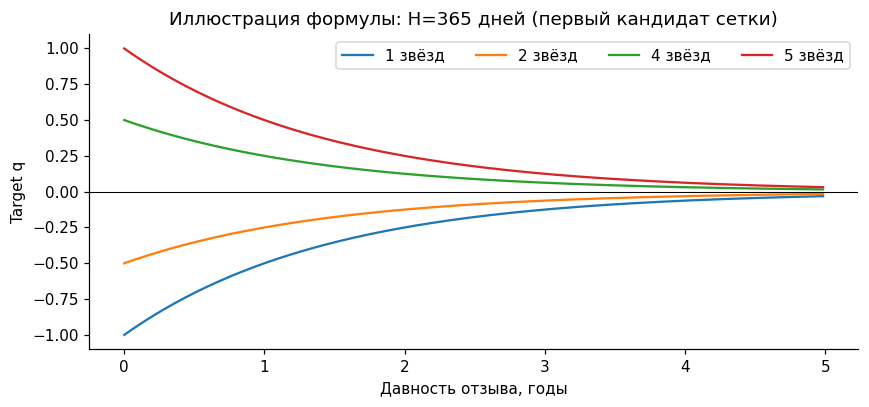

In [24]:
ages = np.arange(0, 5*365+1, 10)
fig, ax = plt.subplots(figsize=(8,3.8))
H = config['models']['CustomALS'][0]['half_life_days']
for rating in [1,2,4,5]:
    ax.plot(ages/365.25, ((rating-3)/2)*2**(-ages/H), label=f'{rating} звёзд')
ax.axhline(0, color='black', lw=.7)
ax.set(xlabel='Давность отзыва, годы', ylabel='Target q', title=f'Иллюстрация формулы: H={H:g} дней (первый кандидат сетки)')
ax.legend(ncol=4)
finish_figure()

## 5. Подбор параметров и проверка обучения

На каждый из пяти методов выделено ровно **4 конфигурации**, критерий выбора — validation NDCG@10.
Сетка небольшая и заранее заданная; исследование сравнивает этот вычислительный бюджет, а не глобальные
оптимумы всех алгоритмов. У CustomALS факторы/регуляризация/полураспад в этой сетке частично связаны;
matched-контроль ниже нужен, чтобы отделить смену target от прочих настроек.
При равных метриках выигрывает более ранняя конфигурация.

После выбора параметры зафиксированы до test. Случайные методы повторяются на seed 42, 123, 2026;
детерминированные KNN, EASE и Popularity — один раз. FM-ID использует параметры основной FM и тот же
negative sampler: это контролируемая абляция, а не независимо оптимизированный конкурент.

In [25]:
"""Run the complete comparison in memory, without loading or saving results.

The notebook supplies prepared data and the experiment configuration. Every
call trains all validation candidates, selects settings using validation only,
refits the selected models, and computes the held-out research tables.
"""
from __future__ import annotations

from copy import deepcopy
from dataclasses import dataclass, field
import gc
import hashlib
import importlib.metadata
import json
import platform
import sys
import time

import numpy as np
import pandas as pd
from threadpoolctl import threadpool_info, threadpool_limits
import torch


PRIMARY = ["ItemKNN", "iALS", "EASE", "FM", "CustomALS"]
CONTROLS = ["Popularity", "FM_ID_only", "CustomALS_matched", "SignedALS_no_decay"]
METRICS = ["NDCG@10", "Recall@10", "Precision@10", "HitRate@10", "MAP@10", "Coverage@10"]


@dataclass
class ExperimentResults:
    """Transient experiment state used directly by notebook cells.

    ``summary`` in ``tables`` is indexed by model; other tables use ordinary
    columns. Trace keys are ("validation", model, trial) or ("test", model,
    seed). Per-user metrics and recommendations use (model, seed) keys.
    There is deliberately no disk serialization or restoration API.
    """

    tables: dict[str, pd.DataFrame] = field(default_factory=dict)
    metadata: dict = field(default_factory=dict)
    traces: dict[tuple[str, str, int], list] = field(default_factory=dict)
    per_users: dict[tuple[str, int], pd.DataFrame] = field(default_factory=dict)
    topks: dict[tuple[str, int], pd.DataFrame] = field(default_factory=dict)


class Popularity:
    """Unpersonalized research control, outside the five required methods."""

    def fit(self, history, n_users, n_items, cutoff=None):
        self.values = np.bincount(
            history.loc[history.rating >= 4, "item_idx"], minlength=n_items,
        ).astype(float)
        return self

    def score_users(self, users):
        return np.broadcast_to(self.values, (len(users), len(self.values))).copy()


def make_model(name, params, seed):
    """Construct a fresh model; all learnable methods are local implementations."""
    args = dict(params)
    if name == "Popularity":
        return Popularity()
    if name == "ItemKNN":
        return ItemKNN(**args)
    if name == "EASE":
        return EASE(**args)
    args["seed"] = seed
    if name == "iALS":
        return ImplicitALS(**args)
    if name in ("FM", "FM_ID_only"):
        args["with_metadata"] = name != "FM_ID_only"
        args["n_threads"] = torch.get_num_threads()
        return FactorizationMachine(**args)
    if name in ("CustomALS", "CustomALS_matched", "SignedALS_no_decay"):
        return CustomTargetALS(**args)
    raise ValueError(f"Unknown model: {name}")


def fit_and_score(name, params, seed, history, heldout, data, k):
    model = make_model(name, params, seed)
    started = time.perf_counter()
    # Timestamps represent indivisible date bundles. +1 marks the logical
    # instant after the final observed bundle, not within-day availability.
    cutoff = int(history.timestamp.max()) + 1
    model.fit(history, data["n_users"], data["n_items"], cutoff=cutoff)
    fit_seconds = time.perf_counter() - started
    started = time.perf_counter()
    metrics, per_user, topk = evaluate_model(
        model, history, heldout, data["n_users"], data["n_items"], k=k,
    )
    score_seconds = time.perf_counter() - started
    trace = getattr(model, "history_", [])
    del model
    gc.collect()
    return metrics, per_user, topk, fit_seconds, score_seconds, trace




def _add_examples(data, results, history):
    reference = results.per_users[("iALS", 42)].sort_values("user_idx")
    # Select by observed history length, independently of recommendations/hits.
    ordered = reference.sort_values(["history_length", "user_idx"])
    selected = [
        int(ordered.iloc[min(int(q * len(ordered)), len(ordered) - 1)].user_idx)
        for q in (0.2, 0.5, 0.9)
    ]
    metadata = data["items"].drop_duplicates("item_idx").copy()
    if "title" not in metadata:
        metadata["title"] = metadata.item_id
    history_rows = history.loc[history.user_idx.isin(selected)].sort_values(["user_idx", "timestamp"])
    history_rows = history_rows.groupby("user_idx", group_keys=False).tail(12)
    history_rows = history_rows.drop(columns=["user_id"], errors="ignore")
    results.tables["example_histories"] = history_rows.merge(
        metadata.drop(columns=["item_id"], errors="ignore"), on="item_idx", how="left",
    )
    truth = set(map(tuple, data["test"].loc[data["test"].rating >= 4, ["user_idx", "item_idx"]].to_numpy()))
    examples = []
    for (model, seed), recommendations in results.topks.items():
        if seed != 42 or model not in PRIMARY + ["Popularity"]:
            continue
        sample = recommendations.loc[recommendations.user_idx.isin(selected)].copy()
        sample["model"] = model
        sample["relevant_in_test"] = [
            tuple(pair) in truth for pair in sample[["user_idx", "item_idx"]].to_numpy()
        ]
        examples.append(sample)
    results.tables["example_recommendations"] = pd.concat(examples).merge(
        metadata, on="item_idx", how="left",
    )
    results.metadata["example_selection"] = {
        "rule": "history-length quantiles 0.2, 0.5, 0.9; tie by user_idx, independent of predictions",
        "users": selected,
    }


def _check_final_run(metrics, per_user, topk, reference_users, history, k):
    """Cheap runtime invariants; fail before interpreting invalid comparisons."""
    users = per_user.user_idx.to_numpy()
    if reference_users is not None and not np.array_equal(users, reference_users):
        raise RuntimeError("Models were evaluated on different cohorts")
    if per_user.user_idx.duplicated().any() or topk.duplicated(["user_idx", "item_idx"]).any():
        raise RuntimeError("Duplicate users or duplicate recommendations")
    if len(topk) != int(per_user.n_recommendations.sum()) or (per_user.n_recommendations > k).any():
        raise RuntimeError("Invalid recommendation count")
    if not np.isfinite(topk.score).all():
        raise RuntimeError("Nonfinite recommendation scores")
    if not topk.item_idx.isin(history.item_idx.unique()).all():
        raise RuntimeError("A cold item entered the recommendation list")
    seen = pd.MultiIndex.from_frame(history[["user_idx", "item_idx"]])
    recommended = pd.MultiIndex.from_frame(topk[["user_idx", "item_idx"]])
    if recommended.isin(seen).any():
        raise RuntimeError("A previously reviewed item entered the recommendation list")
    for metric in METRICS:
        if not np.isfinite(metrics[metric]) or not 0 <= metrics[metric] <= 1 + 1e-12:
            raise RuntimeError(f"Invalid metric {metric}: {metrics[metric]}")
        if metric in per_user and not np.isclose(metrics[metric], per_user[metric].mean()):
            raise RuntimeError(f"Aggregate metric does not match per-user mean: {metric}")
    return users


def _aggregate_research(data, config, results, history):
    final = results.tables["test_runs"]
    summary = final.groupby("model", sort=False)[METRICS + ["fit_seconds", "score_seconds"]].agg(["mean", "std"])
    summary.columns = [f"{metric}_{stat}" for metric, stat in summary.columns]
    results.tables["summary"] = summary
    comparisons = [("Popularity", name) for name in PRIMARY] + [
        ("iALS", "CustomALS"), ("iALS", "CustomALS_matched"),
        ("iALS", "SignedALS_no_decay"), ("SignedALS_no_decay", "CustomALS_matched"),
        ("FM_ID_only", "FM"),
    ]
    intervals = []
    for base, candidate in comparisons:
        for metric in ("NDCG@10", "Recall@10"):
            interval = paired_bootstrap(
                results.per_users[(base, 42)], results.per_users[(candidate, 42)],
                metric=metric, n_bootstrap=config["bootstrap_samples"], seed=2026,
            )
            intervals.append({"baseline": base, "candidate": candidate, **interval})
    results.tables["paired_bootstrap"] = pd.DataFrame(intervals)
    groups = []
    for (name, seed), frame in results.per_users.items():
        grouped = frame.copy()
        grouped["activity_group"] = pd.cut(
            grouped.history_length, bins=[0, 5, 10, 20, np.inf],
            labels=["1–5", "6–10", "11–20", "21+"],
        )
        for group, subset in grouped.groupby("activity_group", observed=True):
            groups.append({
                "model": name, "seed": seed, "activity_group": str(group), "users": len(subset),
                **{metric: subset[metric].mean() for metric in METRICS if metric in subset},
            })
    results.tables["activity_groups"] = pd.DataFrame(groups)
    popularity = history.loc[history.rating >= 4].groupby("item_idx").size()
    counts = history.groupby("item_idx").size()
    catalog = data["items"].copy()
    catalog["positive_train_count"] = catalog.item_idx.map(popularity).fillna(0).astype(int)
    catalog["history_count"] = catalog.item_idx.map(counts).fillna(0).astype(int)
    results.tables["catalog"] = catalog
    concentration = []
    for (name, seed), recommendations in results.topks.items():
        frequencies = recommendations.item_idx.value_counts()
        concentration.append({
            "model": name, "seed": seed, "unique_recommended": len(frequencies),
            "share_top_10_recommended_items": frequencies.head(10).sum() / len(recommendations),
            "mean_log_popularity": np.log1p(recommendations.item_idx.map(popularity).fillna(0)).mean(),
        })
    results.tables["concentration"] = pd.DataFrame(concentration)
    _add_examples(data, results, history)


def run_experiments(data, config, progress=print) -> ExperimentResults:
    """Compute all experiment outputs from fresh fits and return them in memory.

    Parameters
    ----------
    data : dict
        Output of ``prepare_dataset`` (already loaded by the notebook).
    config : dict
        Experiment settings, defined in the notebook parameter cell.
        The supplied configuration has 20 validation fits and 21 final fits.
    progress : callable or None
        Receives a single status string; ``None`` disables status messages.

    This function neither reads cached results nor creates files. Raw source
    archives, if needed, are handled separately by the dataset loader. Test
    labels are used only after all selected settings and ablations are fixed.
    """
    config = deepcopy(config)
    if config["k"] != 10 or config["positive_threshold"] != 4 or 42 not in config["final_seeds"]:
        raise ValueError("The comparison requires k=10, rating threshold=4 and reference seed=42")
    if len(set(config["final_seeds"])) != len(config["final_seeds"]):
        raise ValueError("Final seeds must be unique")
    for name in PRIMARY:
        if not config["models"].get(name):
            raise ValueError(f"No validation candidates configured for {name}")
    if not data["train"].timestamp.max() < data["validation"].timestamp.min():
        raise ValueError("Train and validation overlap in time")
    if not data["validation"].timestamp.max() < data["test"].timestamp.min():
        raise ValueError("Validation and test overlap in time")

    def report(message):
        if progress is not None:
            progress(message)

    started = time.perf_counter()
    results = ExperimentResults(tables=summarize_data(data))
    results.metadata.update({
        "dataset_stats": deepcopy(data["stats"]),
        "experiment_config": config,
        "data_manifest": deepcopy(data["manifest"]),
    })
    config_hash = hashlib.sha256(json.dumps(config, sort_keys=True).encode("utf-8")).hexdigest()
    old_threads = torch.get_num_threads()
    old_determinism = torch.are_deterministic_algorithms_enabled()
    old_warn_only = torch.is_deterministic_algorithms_warn_only_enabled()
    torch.set_num_threads(config["torch_threads"])
    torch.use_deterministic_algorithms(True)
    try:
        with threadpool_limits(limits=config["blas_threads"]):
            tuning_rows, selected = [], {}
            for name in PRIMARY:
                candidates = config["models"][name]
                for trial, params in enumerate(candidates):
                    report(f"Validation {name} {trial + 1}/{len(candidates)}: {params}")
                    metrics, _, _, fit_seconds, score_seconds, trace = fit_and_score(
                        name, params, config["tuning_seed"], data["train"], data["validation"], data, config["k"],
                    )
                    if name == PRIMARY[0] and trial == 0:
                        results.metadata["validation_protocol_audit"] = metrics["evaluation"]
                    tuning_rows.append({
                        "model": name, "trial": trial, "params": json.dumps(params, sort_keys=True),
                        "fit_seconds": fit_seconds, "score_seconds": score_seconds, **metrics,
                    })
                    results.traces[("validation", name, trial)] = trace
                    report(f"  NDCG@10={metrics['NDCG@10']:.5f}; train={fit_seconds:.1f}s eval={score_seconds:.1f}s")
                best = max(
                    (row for row in tuning_rows if row["model"] == name),
                    key=lambda row: (row["NDCG@10"], -row["trial"]),
                )
                selected[name] = json.loads(best["params"])
            results.tables["tuning"] = pd.DataFrame(tuning_rows)
            # Freeze every primary model and research condition before test.
            selected["Popularity"] = {}
            selected["FM_ID_only"] = dict(selected["FM"])
            selected["CustomALS_matched"] = dict(
                selected["iALS"], half_life_days=selected["CustomALS"]["half_life_days"],
            )
            selected["SignedALS_no_decay"] = dict(selected["iALS"], half_life_days=None)
            results.metadata["selected_params"] = selected
            history = pd.concat([data["train"], data["validation"]], ignore_index=True)
            final_rows, reference_users = [], None
            for name in PRIMARY + CONTROLS:
                seeds = [42] if name in ("ItemKNN", "EASE", "Popularity") else config["final_seeds"]
                for seed in seeds:
                    report(f"Final test {name}, seed={seed}")
                    metrics, per_user, topk, fit_seconds, score_seconds, trace = fit_and_score(
                        name, selected[name], seed, history, data["test"], data, config["k"],
                    )
                    reference_users = _check_final_run(metrics, per_user, topk, reference_users, history, config["k"])
                    if name == PRIMARY[0]:
                        results.metadata["test_protocol_audit"] = metrics["evaluation"]
                    final_rows.append({
                        "model": name, "seed": seed,
                        "role": "primary" if name in PRIMARY else "research_control",
                        "fit_seconds": fit_seconds, "score_seconds": score_seconds, **metrics,
                    })
                    results.per_users[(name, seed)] = per_user
                    results.topks[(name, seed)] = topk
                    results.traces[("test", name, seed)] = trace
                    report(f"  NDCG@10={metrics['NDCG@10']:.5f}; train={fit_seconds:.1f}s eval={score_seconds:.1f}s")
            results.tables["test_runs"] = pd.DataFrame(final_rows)
            report("Computing paired bootstrap, activity groups and recommendation diagnostics...")
            _aggregate_research(data, config, results, history)
            active_threadpools = threadpool_info()
    finally:
        torch.set_num_threads(old_threads)
        torch.use_deterministic_algorithms(old_determinism, warn_only=old_warn_only)

    packages = ["numpy", "scipy", "pandas", "torch", "matplotlib", "threadpoolctl"]
    results.metadata["environment"] = {
        "python": sys.version, "platform": platform.platform(), "machine": platform.machine(),
        "packages": {name: importlib.metadata.version(name) for name in packages},
        "threadpools": active_threadpools,
        "elapsed_seconds": time.perf_counter() - started,
        "config_sha256": config_hash,
        "notes": "UTC timestamps; bootstrap intervals condition on seed 42 and are not multiple-test corrected.",
    }
    elapsed_minutes = results.metadata["environment"]["elapsed_seconds"] / 60
    report(f"Finished in {elapsed_minutes:.1f} minutes. All results remain in notebook memory.")
    return results

In [26]:
experiment = run_experiments(data, config, progress=print)
tables = experiment.tables
selected = experiment.metadata['selected_params']
environment = experiment.metadata['environment']
runs = tables['test_runs']
summary = tables['summary']
intervals = tables['paired_bootstrap']
assert experiment.metadata['validation_protocol_audit'] == validation_audit
assert experiment.metadata['test_protocol_audit'] == test_audit
display(pd.Series(environment['packages'], name='version').to_frame())

Validation ItemKNN 1/4: {'top_k': 50, 'shrinkage': 0.0}
  NDCG@10=0.00892; train=0.5s eval=4.6s
Validation ItemKNN 2/4: {'top_k': 50, 'shrinkage': 20.0}
  NDCG@10=0.01937; train=0.7s eval=4.7s
Validation ItemKNN 3/4: {'top_k': 150, 'shrinkage': 0.0}
  NDCG@10=0.00923; train=0.5s eval=3.6s
Validation ItemKNN 4/4: {'top_k': 150, 'shrinkage': 20.0}
  NDCG@10=0.02007; train=0.5s eval=5.0s
Validation iALS 1/4: {'n_factors': 16, 'reg': 1.0, 'alpha': 20.0, 'n_iters': 8}
  NDCG@10=0.01854; train=39.6s eval=4.7s
Validation iALS 2/4: {'n_factors': 16, 'reg': 10.0, 'alpha': 20.0, 'n_iters': 8}
  NDCG@10=0.01865; train=22.1s eval=5.0s
Validation iALS 3/4: {'n_factors': 32, 'reg': 1.0, 'alpha': 20.0, 'n_iters': 8}
  NDCG@10=0.01857; train=33.6s eval=3.9s
Validation iALS 4/4: {'n_factors': 32, 'reg': 10.0, 'alpha': 20.0, 'n_iters': 8}
  NDCG@10=0.01907; train=32.6s eval=3.4s
Validation EASE 1/4: {'reg': 10.0}
  NDCG@10=0.01495; train=54.1s eval=15.6s
Validation EASE 2/4: {'reg': 100.0}
  NDCG@10=0.0

,version
numpy,2.1.3
scipy,1.16.3
pandas,2.2.3
torch,2.11.0+cpu
matplotlib,3.10.0
threadpoolctl,3.7.0


,model,trial,params,NDCG@10,Recall@10,fit_seconds
0,ItemKNN,0,"{""shrinkage"": 0.0, ""top_k"": 50}",0.00892,0.01310,0.45123
1,ItemKNN,1,"{""shrinkage"": 20.0, ""top_k"": 50}",0.01937,0.02846,0.74842
2,ItemKNN,2,"{""shrinkage"": 0.0, ""top_k"": 150}",0.00923,0.01420,0.49737
3,ItemKNN,3,"{""shrinkage"": 20.0, ""top_k"": 150}",0.02007,0.03008,0.54020
4,iALS,0,"{""alpha"": 20.0, ""n_factors"": 16, ""n_iters"": 8, ""reg"": 1.0}",0.01854,0.02895,39.55552
5,iALS,1,"{""alpha"": 20.0, ""n_factors"": 16, ""n_iters"": 8, ""reg"": 10.0}",0.01865,0.02880,22.07291
6,iALS,2,"{""alpha"": 20.0, ""n_factors"": 32, ""n_iters"": 8, ""reg"": 1.0}",0.01857,0.03039,33.61675
7,iALS,3,"{""alpha"": 20.0, ""n_factors"": 32, ""n_iters"": 8, ""reg"": 10.0}",0.01907,0.03089,32.55368
8,EASE,0,"{""reg"": 10.0}",0.01495,0.02353,54.12608
9,EASE,1,"{""reg"": 100.0}",0.01845,0.03032,52.43120


,model,parameters
0,ItemKNN,"{""shrinkage"": 20.0, ""top_k"": 150}"
1,iALS,"{""alpha"": 20.0, ""n_factors"": 32, ""n_iters"": 8, ""reg"": 10.0}"
2,EASE,"{""reg"": 2000.0}"
3,FM,"{""batch_size"": 2048, ""epochs"": 6, ""learning_rate"": 0.01, ""n_factors"": 3..."
4,CustomALS,"{""alpha"": 20.0, ""half_life_days"": 365.0, ""n_factors"": 32, ""n_iters"": 8,..."


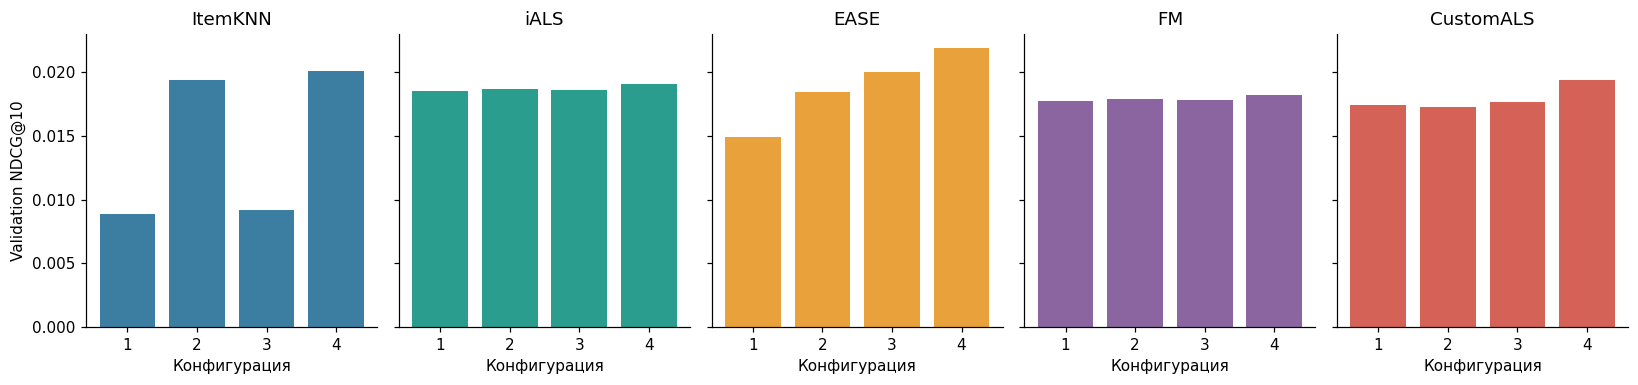

**Что показал подбор.** Средняя validation NDCG ItemKNN без shrinkage — 0.00907, со shrinkage=20 — 0.01972. В этой сетке shrinkage улучшает среднее качество; это согласуется с гипотезой о ненадёжности редких пересечений. Для EASE выбран λ=2000. Лучший параметр среди четырёх кандидатов не обязательно близок к глобальному оптимуму; особенно осторожно следует интерпретировать выбор на границе заданной сетки. Все эти наблюдения относятся к validation, а не к test.

In [27]:
tuning = tables['tuning']
display(tuning[['model','trial','params','NDCG@10','Recall@10','fit_seconds']].round(5))
display(pd.DataFrame([{'model':name, 'parameters':json.dumps(selected[name], ensure_ascii=False)} for name in PRIMARY]))
fig, axes = plt.subplots(1, 5, figsize=(15,3.6), sharey=True)
for ax, name in zip(axes, PRIMARY):
    part = tuning[tuning.model.eq(name)]
    ax.bar(part.trial+1, part['NDCG@10'], color=COLORS[name])
    ax.set(title=name, xlabel='Конфигурация', xticks=[1,2,3,4])
axes[0].set_ylabel('Validation NDCG@10')
finish_figure()
knn_trials = tuning[tuning.model.eq('ItemKNN')].copy()
knn_trials['shrinkage'] = knn_trials.params.map(lambda p: json.loads(p)['shrinkage'])
knn_groups = knn_trials.groupby('shrinkage')['NDCG@10'].mean()
shrinkage_delta = knn_groups.loc[20] - knn_groups.loc[0]
shrinkage_note = (
    'В этой сетке shrinkage улучшает среднее качество; это согласуется с гипотезой о ненадёжности редких пересечений.'
    if shrinkage_delta > 0 else
    'В этой сетке shrinkage не улучшает среднее качество: гипотеза о его пользе здесь не подтверждается.'
)
display(Markdown(
    f"**Что показал подбор.** Средняя validation NDCG ItemKNN без shrinkage — {knn_groups.loc[0]:.5f}, "
    f"со shrinkage=20 — {knn_groups.loc[20]:.5f}. {shrinkage_note} "
    f"Для EASE выбран {selected['EASE']['reg']:g}. "
    "Лучший параметр среди четырёх кандидатов не обязательно близок к глобальному оптимуму; "
    "особенно осторожно следует интерпретировать выбор на границе заданной сетки. "
    "Все эти наблюдения относятся к validation, а не к test."))

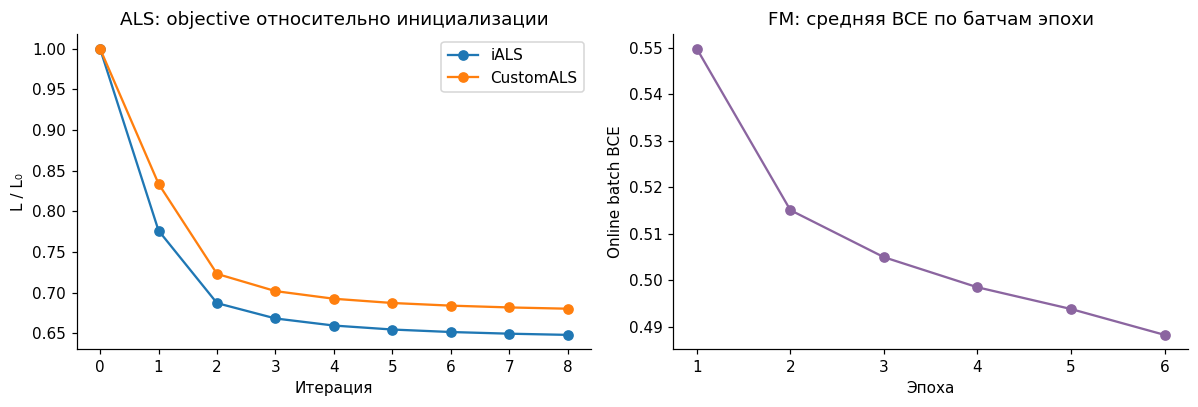

Снижение обучающей ошибки проверяет работу оптимизации, но не доказывает улучшение top-10. Objective двух ALS различается по таргету, поэтому сравнивается динамика внутри модели. У FM показана BCE батчей во время эпохи, а не полная loss на фиксированных финальных весах.

In [28]:
fig, axes = plt.subplots(1,2,figsize=(11,3.8))
for name in ['iALS','CustomALS']:
    trace = pd.DataFrame(experiment.traces[('test', name, 42)])
    numeric_columns = [c for c in trace if 'objective' in c or 'loss' in c]
    if numeric_columns:
        values = trace[numeric_columns[0]].to_numpy()
        axes[0].plot(trace.iteration, values/values[0], marker='o', label=name)
trace = pd.DataFrame(experiment.traces[('test', 'FM', 42)])
axes[1].plot(trace.epoch, trace.bce, marker='o', color=COLORS['FM'])
axes[0].set(title='ALS: objective относительно инициализации', xlabel='Итерация', ylabel='L / L₀')
axes[0].legend()
axes[1].set(title='FM: средняя BCE по батчам эпохи', xlabel='Эпоха', ylabel='Online batch BCE')
finish_figure()
display(Markdown('Снижение обучающей ошибки проверяет работу оптимизации, но не доказывает улучшение top-10. '
                 'Objective двух ALS различается по таргету, поэтому сравнивается динамика внутри модели. '
                 'У FM показана BCE батчей во время эпохи, а не полная loss на фиксированных финальных весах.'))

## 6. H1: качество top-10 и стоимость

В основной таблице **mean ± std по seed** для случайных методов; std отсутствует у детерминированных.
Это разброс обучения, а не доверительный интервал по пользователям. Время обучения отделено от времени
scoring + маскирования + подсчёта метрик; загрузка данных в эти времена не входит.
Popularity — вспомогательный шестой ориентир, не замена одной из пяти обязательных моделей.

,NDCG@10_mean,NDCG@10_std,Recall@10_mean,Precision@10_mean,HitRate@10_mean,MAP@10_mean,Coverage@10_mean,fit_seconds_mean,score_seconds_mean
model,,,,,,,,,
Popularity,0.01856,NaN,0.02375,0.01028,0.04102,0.01394,0.00198,0.00330,2.43722
ItemKNN,0.01415,NaN,0.02213,0.00604,0.04191,0.00890,0.70676,0.98743,4.75350
iALS,0.01681,0.00102,0.02584,0.00683,0.05529,0.01017,0.06277,33.33180,3.79043
EASE,0.01605,NaN,0.02598,0.00654,0.05274,0.00939,0.41759,67.67121,19.17054
FM,0.01800,0.00083,0.02427,0.00964,0.04469,0.01278,0.00569,28.57986,4.14815
CustomALS,0.01594,0.00059,0.02419,0.00635,0.05162,0.00977,0.06365,33.61976,4.17668


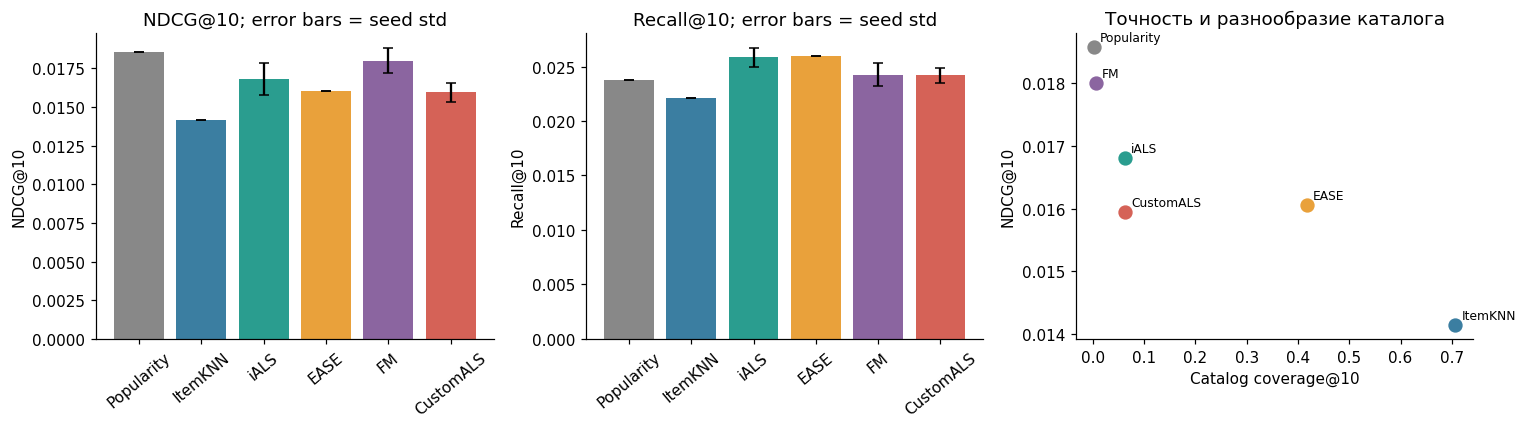

In [29]:
order = ['Popularity'] + PRIMARY
columns = ['NDCG@10_mean','NDCG@10_std','Recall@10_mean','Precision@10_mean',
           'HitRate@10_mean','MAP@10_mean','Coverage@10_mean','fit_seconds_mean','score_seconds_mean']
display(summary.loc[order, columns].round(5))
fig, axes = plt.subplots(1,3,figsize=(14,4))
for ax, metric in zip(axes[:2], ['NDCG@10','Recall@10']):
    means = summary.loc[order, metric+'_mean']
    stds = summary.loc[order, metric+'_std'].fillna(0)
    ax.bar(order, means, yerr=stds, capsize=3, color=[COLORS[n] for n in order])
    ax.set(title=metric+'; error bars = seed std', ylabel=metric)
    ax.tick_params(axis='x', rotation=40)
for name in order:
    row = summary.loc[name]
    axes[2].scatter(row['Coverage@10_mean'],row['NDCG@10_mean'],s=70,color=COLORS[name])
    axes[2].annotate(name,(row['Coverage@10_mean'],row['NDCG@10_mean']),xytext=(4,4),textcoords='offset points',fontsize=8)
axes[2].set(xlabel='Catalog coverage@10',ylabel='NDCG@10',title='Точность и разнообразие каталога')
finish_figure()

In [30]:
best_name = summary.loc[PRIMARY, 'NDCG@10_mean'].idxmax()
best_value = summary.loc[best_name, 'NDCG@10_mean']
pop_value = summary.loc['Popularity','NDCG@10_mean']
evidence = intervals[(intervals.baseline=='Popularity') & (intervals.metric=='NDCG@10')]
display(evidence[['candidate','mean_difference','ci_lower','ci_upper','n_users']].round(6))
significant = evidence.loc[evidence.ci_lower>0,'candidate'].tolist()
h1_verdict = ('В этом бюджете H1 не подтверждена: даже лучшая средняя среди пяти методов ниже Popularity.'
              if best_value <= pop_value else
              'Среднее качество лучшей модели выше Popularity; статистическую убедительность уточняют парные интервалы.')
recall_best = summary.loc[PRIMARY,'Recall@10_mean'].idxmax()
display(Markdown(
    f"**Ответ на H1.** Наибольшая средняя NDCG@10 среди пяти методов у **{best_name}: {best_value:.5f}**; "
    f"популярность даёт **{pop_value:.5f}**, абсолютная разница **{best_value-pop_value:+.5f}**. "
    f"Положительная нижняя граница парного 95% интервала относительно Popularity получена для: **{', '.join(significant) or 'ни одной модели'}**. "
    "Интервалы используют 3 000 bootstrap-выборок одних и тех же пользователей при seed=42; "
    "они не включают неопределённость другого временного периода. "
    "Сравнения исследовательские, без поправки на множественные проверки; лучшая средняя метрика сама по себе не доказывает превосходство над каждым конкурентом."))
display(Markdown(
    f"**Вывод.** {h1_verdict} "
    f"При этом охват каталога у {best_name} равен {summary.loc[best_name,'Coverage@10_mean']:.2%}, "
    f"а лучшая средняя Recall среди пяти методов — у {recall_best} "
    f"({summary.loc[recall_best,'Recall@10_mean']:.5f}). "
    "NDCG учитывает позиции попаданий, Recall — долю найденных релевантных товаров; один порядок моделей "
    "не обязан сохраняться между критериями. Возможные объяснения силы популярности — короткие истории, "
    "концентрация наблюдаемых отзывов и ограниченный бюджет обучения. Эти объяснения требуют отдельной проверки "
    "и не устанавливают общую непригодность персональных моделей."))

,candidate,mean_difference,ci_lower,ci_upper,n_users
0,ItemKNN,-0.004415,-0.007620,-0.001416,5631
2,iALS,-0.001025,-0.004618,0.002391,5631
4,EASE,-0.002514,-0.005998,0.000753,5631
6,FM,-0.001518,-0.002877,-0.000223,5631
8,CustomALS,-0.002092,-0.005545,0.001304,5631


**Ответ на H1.** Наибольшая средняя NDCG@10 среди пяти методов у **FM: 0.01800**; популярность даёт **0.01856**, абсолютная разница **-0.00056**. Положительная нижняя граница парного 95% интервала относительно Popularity получена для: **ни одной модели**. Интервалы используют 3 000 bootstrap-выборок одних и тех же пользователей при seed=42; они не включают неопределённость другого временного периода. Сравнения исследовательские, без поправки на множественные проверки; лучшая средняя метрика сама по себе не доказывает превосходство над каждым конкурентом.

**Вывод.** В этом бюджете H1 не подтверждена: даже лучшая средняя среди пяти методов ниже Popularity. При этом охват каталога у FM равен 0.57%, а лучшая средняя Recall среди пяти методов — у EASE (0.02598). NDCG учитывает позиции попаданий, Recall — долю найденных релевантных товаров; один порядок моделей не обязан сохраняться между критериями. Возможные объяснения силы популярности — короткие истории, концентрация наблюдаемых отзывов и ограниченный бюджет обучения. Эти объяснения требуют отдельной проверки и не устанавливают общую непригодность персональных моделей.

## 7. H3: что даёт новый таргет ALS

Сначала сравним оптимизированные в одинаковом бюджете iALS и CustomALS. Затем отдельно проверим механизм:
iALS → знаковая оценка без времени → знаковая оценка с затуханием. В этой цепочке размерность,
регуляризация, confidence, число итераций и начальные seed одинаковы. Меняется только target.

,NDCG@10_mean,NDCG@10_std,Recall@10_mean,Coverage@10_mean
model,,,,
iALS,0.016808,0.001019,0.025843,0.062773
SignedALS_no_decay,0.015938,0.001089,0.024804,0.058842
CustomALS_matched,0.015944,0.000588,0.024188,0.063654
CustomALS,0.015944,0.000588,0.024188,0.063654


Выбранные на validation настройки CustomALS совпали с matched-контролем. Поэтому эти два ряда одинаковы: они не являются независимыми свидетельствами эффекта.

,baseline,candidate,mean_difference,ci_lower,ci_upper
10,iALS,CustomALS,-0.001067,-0.003309,0.001175
12,iALS,CustomALS_matched,-0.001067,-0.003309,0.001175
14,iALS,SignedALS_no_decay,-0.001283,-0.002687,0.000177
16,SignedALS_no_decay,CustomALS_matched,0.000215,-0.001940,0.002375


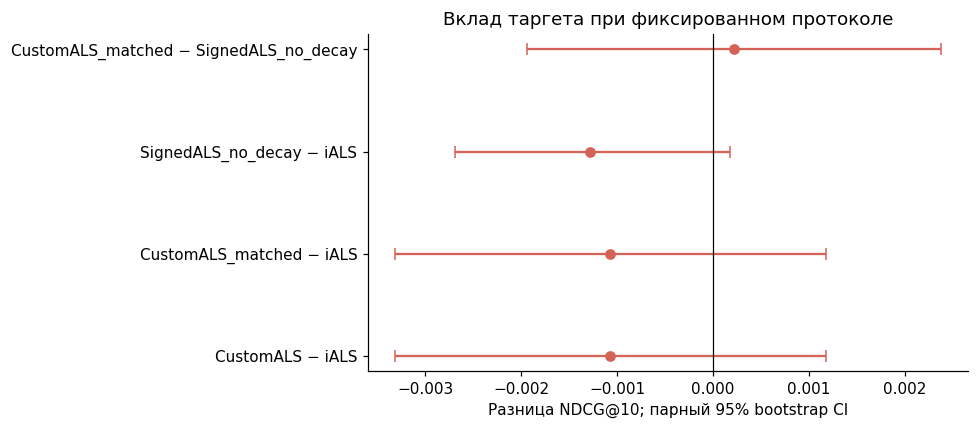

In [31]:
als_order = ['iALS','SignedALS_no_decay','CustomALS_matched','CustomALS']
display(summary.loc[als_order,['NDCG@10_mean','NDCG@10_std','Recall@10_mean','Coverage@10_mean']].round(6))
if selected['CustomALS'] == selected['CustomALS_matched']:
    display(Markdown('Выбранные на validation настройки CustomALS совпали с matched-контролем. '
                     'Поэтому эти два ряда одинаковы: они не являются независимыми свидетельствами эффекта.'))
als_ci = intervals[intervals.baseline.isin(['iALS','SignedALS_no_decay']) & intervals.metric.eq('NDCG@10')]
display(als_ci[['baseline','candidate','mean_difference','ci_lower','ci_upper']].round(6))
fig, ax = plt.subplots(figsize=(9,4))
vals = als_ci.reset_index(drop=True)
labels = vals.candidate + ' − ' + vals.baseline
ax.errorbar(vals.mean_difference, np.arange(len(vals)),
            xerr=np.vstack([vals.mean_difference-vals.ci_lower,vals.ci_upper-vals.mean_difference]),
            fmt='o',capsize=4,color='#D56257')
ax.axvline(0,color='black',lw=.8)
ax.set(yticks=np.arange(len(vals)),yticklabels=labels,xlabel='Разница NDCG@10; парный 95% bootstrap CI',title='Вклад таргета при фиксированном протоколе')
finish_figure()

In [32]:
def contrast(base, candidate, metric='NDCG@10'):
    return intervals[(intervals.baseline==base)&(intervals.candidate==candidate)&(intervals.metric==metric)].iloc[0]
def direction(row):
    if row.ci_lower > 0: return 'положительный эффект подтверждён этим интервалом'
    if row.ci_upper < 0: return 'качество снижается, интервал целиком ниже нуля'
    return 'интервал пересекает ноль: убедительного отличия в этом запуске нет'
signed = contrast('iALS','SignedALS_no_decay')
time_effect = contrast('SignedALS_no_decay','CustomALS_matched')
overall = contrast('iALS','CustomALS')
display(Markdown(
    f"**Ответ на H3.** Смена бинарного сигнала на знаковую оценку без времени: ΔNDCG={signed.mean_difference:+.5f}; {direction(signed)}. "
    f"Добавление затухания к тому же знаковому сигналу: ΔNDCG={time_effect.mean_difference:+.5f}; {direction(time_effect)}. "
    f"Итоговое сравнение отдельно подобранных моделей: ΔNDCG={overall.mean_difference:+.5f}; {direction(overall)}.\n\n"
    "Оценивать пользу затухания следует именно по сравнению со знаковым сигналом без времени: "
    "если его интервал пересекает ноль, данные не позволяют уверенно приписать разницу давности отзывов. "
    "Содержательный риск предложенной цели — ослабление редких положительных наблюдений, даже когда они отражают устойчивый интерес. "
    "Это возможное объяснение, а не установленная причинная модель поведения. "
    "Для проверки переноса вывода нужны другие временные окна и категории, которые здесь не использованы для подбора."))

**Ответ на H3.** Смена бинарного сигнала на знаковую оценку без времени: ΔNDCG=-0.00128; интервал пересекает ноль: убедительного отличия в этом запуске нет. Добавление затухания к тому же знаковому сигналу: ΔNDCG=+0.00022; интервал пересекает ноль: убедительного отличия в этом запуске нет. Итоговое сравнение отдельно подобранных моделей: ΔNDCG=-0.00107; интервал пересекает ноль: убедительного отличия в этом запуске нет.

Оценивать пользу затухания следует именно по сравнению со знаковым сигналом без времени: если его интервал пересекает ноль, данные не позволяют уверенно приписать разницу давности отзывов. Содержательный риск предложенной цели — ослабление редких положительных наблюдений, даже когда они отражают устойчивый интерес. Это возможное объяснение, а не установленная причинная модель поведения. Для проверки переноса вывода нужны другие временные окна и категории, которые здесь не использованы для подбора.

## 8. H2: полезны ли метапризнаки FM

FM-ID и основная FM обучаются на тех же наблюдениях и sampled negatives, с теми же настройками,
эпохами и seed. Разница — восемь исторических/календарных признаков. Внутри FM случайная
инициализация дополнительных параметров может менять траекторию обучения; три seed помогают оценить устойчивость.

,NDCG@10_mean,NDCG@10_std,Recall@10_mean,Coverage@10_mean
model,,,,
FM_ID_only,0.017934,0.000122,0.024036,0.005975
FM,0.018000,0.000826,0.024269,0.005692


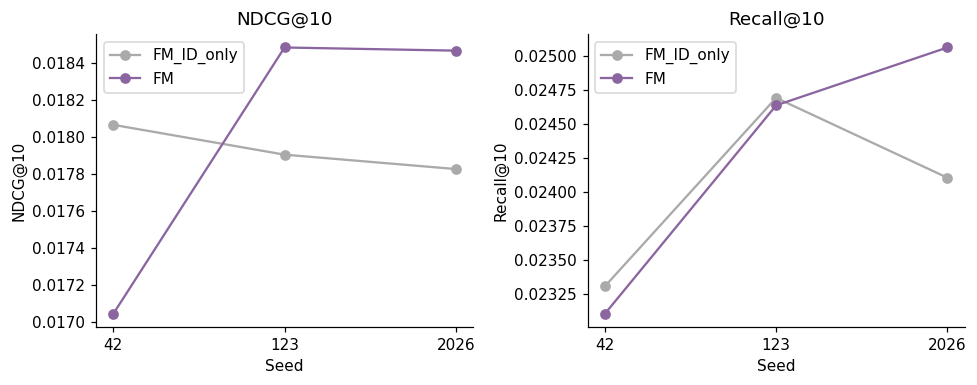

**Ответ на H2.** При seed=42 разница FM − FM-ID составляет **-0.00102 NDCG@10**, 95% CI [-0.00276; +0.00067]: интервал пересекает ноль: убедительного отличия в этом запуске нет. Этот контроль оценивает набор признаков целиком и не выделяет вклад каждого из восьми полей. Результат также зависит от выбранных negative sampling и бюджета обучения; FM-ID отдельно не перенастраивалась.

In [33]:
display(summary.loc[['FM_ID_only','FM'],['NDCG@10_mean','NDCG@10_std','Recall@10_mean','Coverage@10_mean']].round(6))
fm_effect = contrast('FM_ID_only','FM')
fig, axes = plt.subplots(1,2,figsize=(9,3.6))
for ax, metric in zip(axes,['NDCG@10','Recall@10']):
    for name, color in [('FM_ID_only','#AAAAAA'),('FM',COLORS['FM'])]:
        part = runs[runs.model.eq(name)]
        ax.plot(part.seed.astype(str),part[metric],marker='o',label=name,color=color)
    ax.set(title=metric,xlabel='Seed',ylabel=metric)
    ax.legend()
finish_figure()
display(Markdown(
    f"**Ответ на H2.** При seed=42 разница FM − FM-ID составляет **{fm_effect.mean_difference:+.5f} NDCG@10**, "
    f"95% CI [{fm_effect.ci_lower:+.5f}; {fm_effect.ci_upper:+.5f}]: {direction(fm_effect)}. "
    "Этот контроль оценивает набор признаков целиком и не выделяет вклад каждого из восьми полей. "
    "Результат также зависит от выбранных negative sampling и бюджета обучения; FM-ID отдельно не перенастраивалась."))

### 8.1. Почему метапризнаки могут помогать — и где появляется смещение

Следующие графики построены **только по train**. Они проверяют наличие наблюдаемого сигнала в признаках
и показывают свойства выбранного negative sampler. Первые отзывы с отсутствующей историей выделены
отдельно: подставленное среднее 3 не является наблюдавшейся пользовательской оценкой.

In [34]:
"""Training-only research on causal FM features and negative sampling.

The notebook supplies the prepared data and experiment configuration. Every
summary is computed in memory; this module neither reads nor writes data files.
"""
import numpy as np
import pandas as pd



def _quantiles(values):
    probabilities = [0.0, 0.1, 0.5, 0.9, 1.0]
    quantiles = np.quantile(values, probabilities)
    return {key: float(value) for key, value in zip(
        ["minimum", "p10", "median", "p90", "maximum"], quantiles)}


def _signal_rows(name, categories, labels, bin_labels):
    rows = []
    for order, label in enumerate(bin_labels):
        included = categories == label
        count = int(included.sum())
        positives = int(labels[included].sum())
        rows.append({"feature": name, "bin": label, "bin_order": order,
                     "n": count, "positives": positives,
                     "positive_rate": positives / count if count else np.nan})
    assert sum(row["n"] for row in rows) == len(labels)
    return rows


def _histogram_rows(name, counts):
    bin_labels = ["0", "1–4", "5–19", "20–99", "100+"]
    categories = pd.cut(counts, [-1, 0, 4, 19, 99, np.inf], labels=bin_labels)
    rows = []
    for order, label in enumerate(bin_labels):
        count = int((categories == label).sum())
        rows.append({"sample_kind": name, "bin": label, "bin_order": order,
                     "n": count, "total": len(counts), "share": count / len(counts)})
    assert sum(row["n"] for row in rows) == len(counts)
    return rows


def analyze_features(data: dict, config: dict) -> dict:
    """Return feature tables and an audit computed exclusively from the training split.

    ``data`` is the dictionary returned by ``prepare_dataset``; ``config`` is
    the shared experiment configuration used by the notebook. FM candidates
    must share a negative sampling ratio so that this single diagnostic describes
    their common training protocol. No validation or test labels inform features.
    """
    if config.get("positive_threshold", 4) != 4:
        raise ValueError("The feature protocol defines positive reviews as rating >= 4")
    ratios = {int(candidate.get("negative_ratio", 2))
              for candidate in config["models"]["FM"]}
    if len(ratios) != 1 or min(ratios) < 1:
        raise ValueError("FM feature research requires a shared positive negative_ratio")
    negative_ratio = ratios.pop()
    seed = int(config["tuning_seed"])
    events, train = data["events"], data["train"]
    validation, test = data["validation"], data["test"]
    cutoffs = data["cutoffs"]
    n_users, n_items = data["n_users"], data["n_items"]
    archive_hash = data["manifest"]["files"]["Musical_Instruments_5.json.gz"]["sha256"]
    cleaning = {key: data["stats"][key] for key in
                ("raw_interactions", "invalid_interactions_removed", "duplicate_user_item_removed")}
    features = CausalFeatureStore(train, n_users, n_items)
    users = train.user_idx.to_numpy(dtype=np.int64)
    items = train.item_idx.to_numpy(dtype=np.int64)
    timestamps = train.timestamp.to_numpy(dtype=np.int64)
    positive = train.rating.to_numpy() >= 4
    user_numeric, item_numeric = features.pair_features(users, items, timestamps)
    user_count, user_mean, _ = features.user_history.query(users, timestamps)
    item_count, _, _ = features.item_history.query(items, timestamps)
    combined = np.column_stack((user_numeric, item_numeric))
    assert np.isfinite(combined).all()
    names = USER_FEATURE_NAMES + ITEM_FEATURE_NAMES
    summaries = []
    for index, name in enumerate(names):
        column = combined[:, index]
        group = "user" if index < len(USER_FEATURE_NAMES) else "item"
        is_calendar = name.startswith("calendar_")
        prior_default = 0.0 if is_calendar else float(
            ((user_count == 0) if group == "user" else (item_count == 0)).mean())
        summaries.append({"feature": name, "group": group,
                          "n": len(column), "mean": float(column.mean(dtype=np.float64)),
                          "std": float(column.std(dtype=np.float64)),
                          "prior_default_fraction": prior_default,
                          **_quantiles(column)})

    # A missing history is kept separate from an actual historical mean of 3.
    mean_labels = ["1–2", "(2,3]", "(3,4]", "(4,5]"]
    mean_groups = np.asarray(pd.cut(user_mean, [0, 2, 3, 4, 5], labels=mean_labels),
                             dtype=object)
    mean_groups[user_count == 0] = "no_prior_history"
    count_labels = ["0", "1–4", "5–19", "20+"]
    count_groups = np.asarray(pd.cut(item_count, [-1, 0, 4, 19, np.inf],
                                    labels=count_labels), dtype=object)
    signals = _signal_rows("prior_user_mean_rating", mean_groups, positive,
                           ["no_prior_history"] + mean_labels)
    signals.extend(_signal_rows("prior_item_count", count_groups, positive, count_labels))

    sampled_users, sampled_items, sampled_times, sampled_labels = sample_training_pairs(
        train, n_items, negative_ratio=negative_ratio, seed=seed)
    del sampled_users
    observed_count = len(train)
    negative_items, negative_times = sampled_items[observed_count:], sampled_times[observed_count:]
    negative_counts, _, _ = features.item_history.query(negative_items, negative_times)
    positive_counts = item_count[positive]
    assert len(negative_counts) > 0
    assert np.all(negative_counts > 0), "Sampled items must exist strictly before their event"
    assert np.all(sampled_labels[observed_count:] == 0)
    histogram = _histogram_rows("observed_positive", positive_counts)
    histogram.extend(_histogram_rows("sampled_negative", negative_counts))
    first_time_user_events = int((user_count == 0).sum())
    first_time_item_events = int((item_count == 0).sum())
    audit = {
        "scope": "Training split only; validation/test used only for the common chronological partition and ID vocabulary",
        "reviews_archive_sha256": archive_hash,
        "cleaning": cleaning,
        "clean_interactions": len(events), "n_users": int(n_users), "n_items": int(n_items),
        "train_interactions": len(train), "train_users": int(train.user_idx.nunique()),
        "train_items": int(train.item_idx.nunique()),
        "validation_interactions": len(validation), "test_interactions": len(test),
        "train_positive_interactions": int(positive.sum()),
        "train_positive_fraction": float(positive.mean()),
        "train_end_timestamp": cutoffs["train_end"],
        "train_end_utc": pd.to_datetime(cutoffs["train_end"], unit="s", utc=True).isoformat(),
        "train_zero_prior_user_events": first_time_user_events,
        "train_zero_prior_user_fraction": float((user_count == 0).mean()),
        "train_zero_prior_item_events": first_time_item_events,
        "train_zero_prior_item_fraction": float((item_count == 0).mean()),
        "extra_user_events_at_first_user_timestamp": first_time_user_events - int(train.user_idx.nunique()),
        "extra_item_events_at_first_item_timestamp": first_time_item_events - int(train.item_idx.nunique()),
        "train_events_with_repeated_user_timestamp_fraction": float(train.duplicated(["user_idx", "timestamp"], keep=False).mean()),
        "all_clean_timestamps_are_whole_utc_days": bool((events.timestamp.to_numpy() % 86400 == 0).all()),
        "train_whole_utc_day_timestamp_fraction": float((timestamps % 86400 == 0).mean()),
        "train_distinct_timestamps": int(train.timestamp.nunique()),
        "sampling_seed": seed, "negative_ratio_per_positive": negative_ratio,
        "training_pairs": len(sampled_items), "sampled_negative_pairs": len(negative_counts),
        "requested_sampled_negative_pairs": int(positive.sum()) * negative_ratio,
        "unresolved_negative_draws_skipped": int(positive.sum()) * negative_ratio - len(negative_counts),
        "observed_positive_prior_item_count": {"mean": float(positive_counts.mean()), **_quantiles(positive_counts)},
        "sampled_negative_prior_item_count": {"mean": float(negative_counts.mean()), **_quantiles(negative_counts)},
        "feature_names": list(names),
        "notes": [
            "All feature queries use timestamp strictly less than the event, including equal-time reviews from the same user.",
            "Counts are scaled by log1p(count)/log(1001); rating means by /5; positive share is unchanged.",
            "Zero-history defaults are mean rating 3 and positive share 0.5; they are not empirical observations.",
            "Positive-rate plots describe ratings conditional on observed reviews, not purchase probabilities or causal effects.",
            "Synthetic negatives are uniform within the previously observed catalog, excluding user-reviewed pairs at or before the event.",
            "Repeated negative draws are allowed; future positives are eligible negatives until they are observed.",
            "The first positive review of an item may have zero prior item count; sampled negatives always have nonzero prior count by construction.",
            "This diagnostic analysis does not select model parameters or change the predefined experiment configuration.",
        ],
    }
    return {
        "tables": {
            "fm_feature_summary": pd.DataFrame(summaries),
            "fm_feature_signal": pd.DataFrame(signals),
            "fm_sampling_popularity": pd.DataFrame(histogram),
        },
        "audit": audit,
    }

,feature,group,n,mean,std,prior_default_fraction,minimum,p10,median,p90,maximum
0,log_user_count,user,175360,0.1524,0.1406,0.3384,0.0,0.0000,0.1590,0.3471,0.7852
1,user_mean_rating,user,175360,0.7876,0.1821,0.3384,0.2,0.6000,0.8000,1.0000,1.0000
2,user_positive_share,user,175360,0.7340,0.2646,0.3384,0.0,0.5000,0.7778,1.0000,1.0000
3,calendar_sin,user,175360,0.0144,0.6942,0.0000,-1.0,-0.9419,0.0394,0.9401,1.0000
4,calendar_cos,user,175360,0.0924,0.7137,0.0000,-1.0,-0.9341,0.1907,0.9708,1.0000
5,log_item_count,item,175360,0.4127,0.2468,0.0603,0.0,0.1003,0.3820,0.7698,1.0542
6,item_mean_rating,item,175360,0.8781,0.1148,0.0603,0.2,0.7143,0.9105,1.0000,1.0000
7,item_positive_share,item,175360,0.8509,0.1765,0.0603,0.0,0.5122,0.9091,1.0000,1.0000


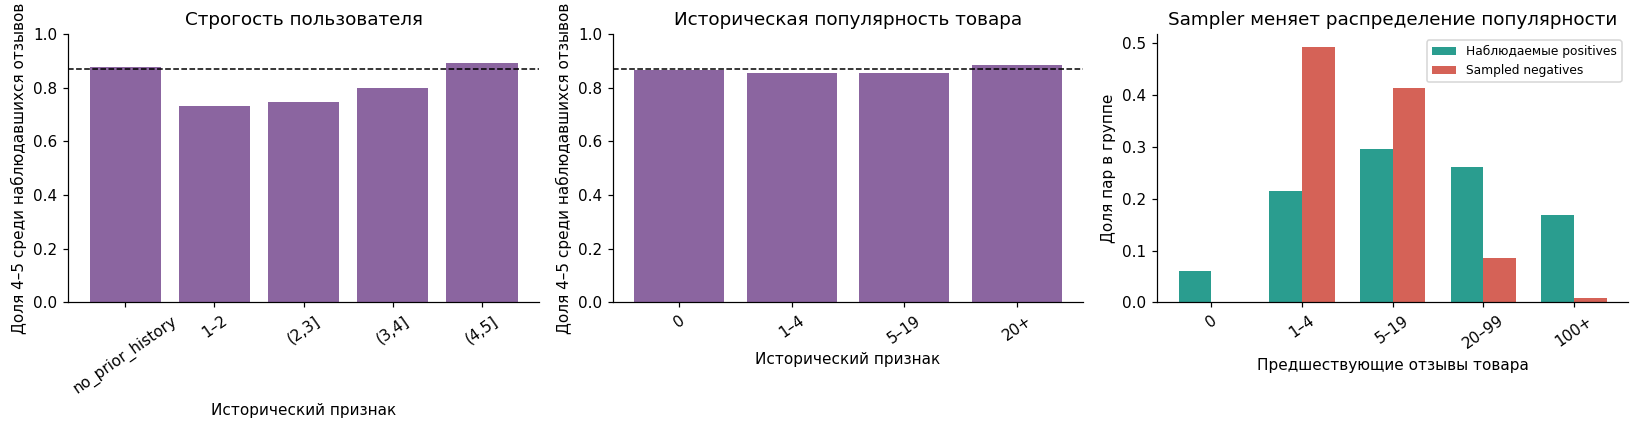

In [35]:
feature_research = analyze_features(data, config)
feature_audit = feature_research['audit']
feature_signal = feature_research['tables']['fm_feature_signal']
sampling = feature_research['tables']['fm_sampling_popularity']
user_signal = feature_signal[feature_signal.feature.eq('prior_user_mean_rating')].set_index('bin')
display(feature_research['tables']['fm_feature_summary'].round(4))
fig, axes = plt.subplots(1,3,figsize=(15,4))
for ax, feature, title in [(axes[0],'prior_user_mean_rating','Строгость пользователя'),
                           (axes[1],'prior_item_count','Историческая популярность товара')]:
    part = feature_signal[feature_signal.feature.eq(feature)].sort_values('bin_order')
    ax.bar(part['bin'],part.positive_rate,color='#8B65A0')
    ax.axhline(feature_audit['train_positive_fraction'],ls='--',color='black',lw=1,label='Средняя по train')
    ax.set(title=title,xlabel='Исторический признак',ylabel='Доля 4–5 среди наблюдавшихся отзывов',ylim=(0,1))
    ax.tick_params(axis='x',rotation=35)
hist = sampling.pivot(index='bin_order',columns='sample_kind',values='share').sort_index()
labels = sampling.drop_duplicates('bin_order').sort_values('bin_order')['bin'].tolist()
x = np.arange(len(labels))
axes[2].bar(x-.18,hist.observed_positive,width=.36,label='Наблюдаемые positives',color='#2A9D8F')
axes[2].bar(x+.18,hist.sampled_negative,width=.36,label='Sampled negatives',color='#D56257')
axes[2].set(xticks=x,xticklabels=labels,title='Sampler меняет распределение популярности',xlabel='Предшествующие отзывы товара',ylabel='Доля пар в группе')
axes[2].tick_params(axis='x',rotation=35)
axes[2].legend(fontsize=8)
finish_figure()

In [36]:
positive_median = feature_audit['observed_positive_prior_item_count']['median']
negative_median = feature_audit['sampled_negative_prior_item_count']['median']
if negative_median < positive_median:
    sampling_note = 'В текущем train sampled negatives имеют меньшую медианную историческую популярность, чем positives. '
elif negative_median > positive_median:
    sampling_note = 'В текущем train sampled negatives имеют большую медианную историческую популярность, чем positives. '
else:
    sampling_note = 'Медианы исторической популярности совпадают; различия остальных частей распределения видны на гистограмме. '
timestamp_note = (
    'Все timestamps приходятся на границы UTC-дней. '
    if feature_audit['all_clean_timestamps_are_whole_utc_days'] else
    'Часть timestamps имеет внутридневную точность. '
)
display(Markdown(
    f"**Доступность истории.** В {feature_audit['train_zero_prior_user_fraction']:.2%} обучающих событий "
    f"нет строго предшествующей истории пользователя; у товаров таких случаев {feature_audit['train_zero_prior_item_fraction']:.2%}. "
    f"{timestamp_note} Несколько отзывов с одинаковым timestamp не следует превращать "
    "в искусственную последовательность: их порядок неизвестен. Поэтому причинно корректные признаки "
    "могут использовать cold-history defaults даже для пользователей официального 5-core.\n\n"
    f"**Смещение sampler.** Медиана числа предшествующих отзывов товара у positives равна "
    f"{positive_median:.0f}, у sampled negatives — {negative_median:.0f}. {sampling_note} "
    "FM может использовать популярность для различения обучающих классов; это помогает объяснить, почему "
    "обучающая BCE и полнокаталожная NDCG могут вести себя по-разному. "
    "Доли положительных отзывов на первых двух графиках условны на наличии отзыва, не являются вероятностями покупки "
    "и не доказывают причинного эффекта признаков. Настройки по этим графикам не менялись."))
low, high = user_signal.loc['1–2'], user_signal.loc['(4,5]']
display(Markdown(
    f"**Измеренный сигнал.** При исторической средней оценке 1–2 доля текущих отзывов train "
    f"с оценкой 4–5 равна {low.positive_rate:.2%} (n={int(low.n):,}); "
    f"при средней выше 4 — {high.positive_rate:.2%} (n={int(high.n):,}). "
    f"Разница — {100*(high.positive_rate-low.positive_rate):.2f} процентного пункта. "
    "Это описательное сравнение групп, выделенных по предшествующей строгости пользователя; "
    "FM-ID контроль выше проверяет, превращается ли этот сигнал в улучшение ранжирования."))

**Доступность истории.** В 33.84% обучающих событий нет строго предшествующей истории пользователя; у товаров таких случаев 6.03%. Все timestamps приходятся на границы UTC-дней.  Несколько отзывов с одинаковым timestamp не следует превращать в искусственную последовательность: их порядок неизвестен. Поэтому причинно корректные признаки могут использовать cold-history defaults даже для пользователей официального 5-core.

**Смещение sampler.** Медиана числа предшествующих отзывов товара у positives равна 14, у sampled negatives — 5. В текущем train sampled negatives имеют меньшую медианную историческую популярность, чем positives.  FM может использовать популярность для различения обучающих классов; это помогает объяснить, почему обучающая BCE и полнокаталожная NDCG могут вести себя по-разному. Доли положительных отзывов на первых двух графиках условны на наличии отзыва, не являются вероятностями покупки и не доказывают причинного эффекта признаков. Настройки по этим графикам не менялись.

**Измеренный сигнал.** При исторической средней оценке 1–2 доля текущих отзывов train с оценкой 4–5 равна 73.40% (n=3,007); при средней выше 4 — 89.13% (n=85,764). Разница — 15.73 процентного пункта. Это описательное сравнение групп, выделенных по предшествующей строгости пользователя; FM-ID контроль выше проверяет, превращается ли этот сигнал в улучшение ранжирования.

## 9. H4: кому помогают модели и насколько концентрируются рекомендации

Группы истории определены заранее: 1–5, 6–10, 11–20 и 21+ отзывов до test. Это диагностический
разрез test после фиксации параметров. Нельзя выбирать по нему новые настройки и выдавать тот же test
за независимую проверку. Длина истории не рандомизирована, поэтому разница групп не является причинным эффектом активности.

model,CustomALS,EASE,FM,ItemKNN,Popularity,iALS
activity_group,,,,,,
1–5,0.01754,0.01810,0.02303,0.01498,0.02375,0.01909
6–10,0.01411,0.01602,0.01281,0.01649,0.01415,0.01569
11–20,0.01294,0.00962,0.01063,0.00676,0.01091,0.01171
21+,0.01635,0.01083,0.01145,0.01110,0.00729,0.01171


**Изменение NDCG@10 относительно Popularity в каждой группе:**

model,ItemKNN,iALS,EASE,FM,CustomALS
activity_group,,,,,
1–5,-0.00877,-0.00466,-0.00565,-0.00072,-0.00621
6–10,0.00234,0.00154,0.00187,-0.00134,-0.00004
11–20,-0.00415,0.00080,-0.00130,-0.00029,0.00203
21+,0.00381,0.00442,0.00354,0.00416,0.00906


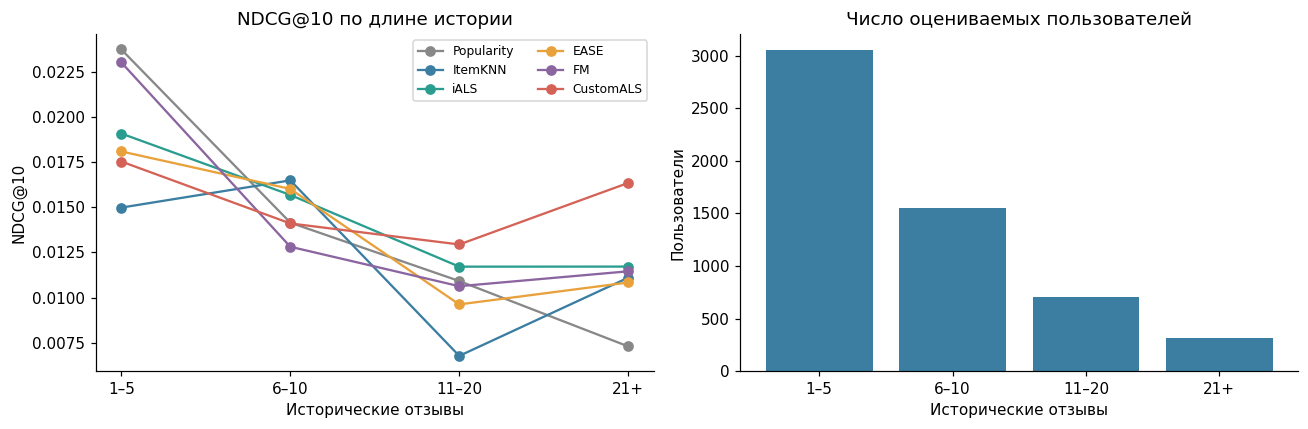

In [37]:
groups = tables['activity_groups']
group_order = ['1–5','6–10','11–20','21+']
group_means = groups[groups.model.isin(PRIMARY+['Popularity'])].groupby(['activity_group','model'])['NDCG@10'].mean().unstack().reindex(group_order)
display(group_means.round(5))
group_lifts = group_means[PRIMARY].subtract(group_means['Popularity'],axis=0)
display(Markdown('**Изменение NDCG@10 относительно Popularity в каждой группе:**'))
display(group_lifts.round(5))
counts = groups[(groups.model=='iALS')&(groups.seed==42)].set_index('activity_group').users.reindex(group_order)
fig, axes = plt.subplots(1,2,figsize=(12,4))
for name in ['Popularity']+PRIMARY:
    axes[0].plot(group_order,group_means[name],marker='o',label=name,color=COLORS[name])
axes[0].set(title='NDCG@10 по длине истории',xlabel='Исторические отзывы',ylabel='NDCG@10')
axes[0].legend(ncol=2,fontsize=8)
axes[1].bar(group_order,counts,color='#3B7EA1')
axes[1].set(title='Число оцениваемых пользователей',xlabel='Исторические отзывы',ylabel='Пользователи')
finish_figure()

,unique_recommended,share_top_10_recommended_items,mean_log_popularity
model,,,
Popularity,21.0000,0.9640,7.0643
ItemKNN,7491.0000,0.1885,4.3243
iALS,665.3333,0.1285,5.3195
EASE,4426.0000,0.2941,5.3550
FM,60.3333,0.7792,6.6517
CustomALS,674.6667,0.1386,5.2536


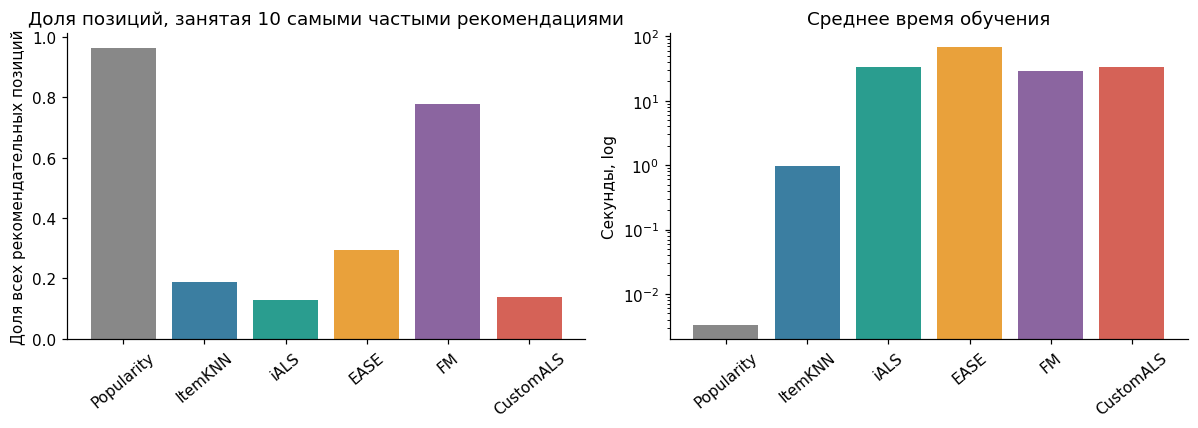

**Ответ на H4.** Самая многочисленная группа — **1–5** отзывов (3,052 пользователей); в ней наибольшая средняя NDCG у **Popularity**. Самый широкий охват каталога среди пяти моделей у **ItemKNN** (70.7%). Охват и концентрация дополняют точность: высокая метрика на популярных товарах может сопровождаться повторением небольшого списка у многих пользователей. Coverage не измеряет смысловое разнообразие внутри одного top-10.

In [38]:
concentration = tables['concentration'].groupby('model').mean(numeric_only=True)
display(concentration.loc[['Popularity']+PRIMARY,['unique_recommended','share_top_10_recommended_items','mean_log_popularity']].round(4))
fig, axes = plt.subplots(1,2,figsize=(11,4))
order = ['Popularity']+PRIMARY
axes[0].bar(order,concentration.loc[order,'share_top_10_recommended_items'],color=[COLORS[n] for n in order])
axes[0].set(title='Доля позиций, занятая 10 самыми частыми рекомендациями',ylabel='Доля всех рекомендательных позиций')
axes[0].tick_params(axis='x',rotation=40)
axes[1].bar(order,summary.loc[order,'fit_seconds_mean'],color=[COLORS[n] for n in order])
axes[1].set(yscale='log',title='Среднее время обучения',ylabel='Секунды, log')
axes[1].tick_params(axis='x',rotation=40)
finish_figure()
largest_group = counts.idxmax()
largest_group_best = group_means.loc[largest_group].idxmax()
coverage_best = summary.loc[PRIMARY,'Coverage@10_mean'].idxmax()
display(Markdown(
    f"**Ответ на H4.** Самая многочисленная группа — **{largest_group}** отзывов ({int(counts.max()):,} пользователей); "
    f"в ней наибольшая средняя NDCG у **{largest_group_best}**. "
    f"Самый широкий охват каталога среди пяти моделей у **{coverage_best}** "
    f"({summary.loc[coverage_best,'Coverage@10_mean']:.1%}). "
    "Охват и концентрация дополняют точность: высокая метрика на популярных товарах может сопровождаться "
    "повторением небольшого списка у многих пользователей. Coverage не измеряет смысловое разнообразие внутри одного top-10."))

## 10. Персональные рекомендации: проверка содержательного смысла

Три пользователя выбраны детерминированно по квантилям длины истории 20%, 50%, 90%, до анализа попаданий.
Это защищает от показа только удачных примеров. Названия/категории — описательный снимок каталога;
они не участвовали в обучении. Отсутствие отметки `relevant_in_test` означает отсутствие положительного
отзыва в данном test-окне, а не доказанную незаинтересованность.

In [39]:
example_users = experiment.metadata['example_selection']['users']
example_history = tables['example_histories']
example_recs = tables['example_recommendations']
for user in example_users:
    display(Markdown(f'### Пользователь {user}: последние наблюдавшиеся отзывы'))
    display(example_history[example_history.user_idx.eq(user)][['title','rating','category']].tail(6))
    preview = example_recs[example_recs.user_idx.eq(user)&example_recs['rank'].le(3)&example_recs.model.isin(PRIMARY)]
    display(preview[['model','rank','title','relevant_in_test']])

### Пользователь 15822: последние наблюдавшиеся отзывы

,title,rating,category
12,"midiplus Midi Controller, 32-Key (AKM320)",5,Studio Recording Equipment
13,CAD Audio U37 USB Studio Condenser Recording Microphone,5,Microphones & Accessories
14,midiplus AK490 MIDI Keyboard Controller,5,Studio Recording Equipment


,model,rank,title,relevant_in_test
10,ItemKNN,1,"Dragonpad USA 6"" Microphone Studio Pop Filter with Clamp - Pink/White",False
11,ItemKNN,2,CAD Audio EPF-15A Pop Filter on 6-inch Gooseneck,False
12,ItemKNN,3,"NEEWER Adjustable Microphone Suspension Boom Scissor Arm Stand, Max Loa...",False
40,iALS,1,"Dragonpad USA 6"" Microphone Studio Pop Filter with Clamp - Pink/White",False
41,iALS,2,"NEEWER Adjustable Microphone Suspension Boom Scissor Arm Stand, Max Loa...",False
42,iALS,3,Neewer NW(B-3) 6 inch Studio Microphone Mic Round Shape Wind Pop Filter...,False
70,EASE,1,"Dragonpad USA 6"" Microphone Studio Pop Filter with Clamp - Pink/White",False
71,EASE,2,"NEEWER Adjustable Microphone Suspension Boom Scissor Arm Stand, Max Loa...",False
72,EASE,3,DAddario Accessories Pro-Winder Guitar String Winder and Cutter All-In-...,False
100,FM,1,"D'Addario EXL120+ Nickel Wound Electric Guitar Strings, Super Light Plu...",False


### Пользователь 18091: последние наблюдавшиеся отзывы

,title,rating,category
15,"Gibson 2016 T Les Paul Studio 60's Tribute Electric Guitar, Satin Ebony",5,Guitars
16,DAddario Accessories Pro-Winder Guitar String Winder and Cutter All-In-...,3,Instrument Accessories
17,"PocketStrings Guitar Practice Tool (Black, 6-Fret)",1,Instrument Accessories
18,"ESP LTD M-17 7-String Electric Guitar, Black",5,Guitars
19,"Dunlop 427PJP John Petrucci Jazz III, 6/Player's Pack",5,Instrument Accessories


,model,rank,title,relevant_in_test
20,ItemKNN,1,Dunlop 427BJP John Petrucci Signature Jazz III Picks - 36 Pack,False
21,ItemKNN,2,"Dunlop 471P3C Max Grip Jazz III Carbon Fiber Guitar Picks, 6-Pack",False
22,ItemKNN,3,Planet Waves 100 Pack Black Ice Medium Guitar Picks,False
50,iALS,1,"D'Addario EXL120-7 Nickel Wound 7-String Electric Guitar Strings, Super...",False
51,iALS,2,"D'Addario EXL120+ Nickel Wound Electric Guitar Strings, Super Light Plu...",False
52,iALS,3,"D'Addario EJ21 Nickel Wound Electric Guitar Strings, Jazz Light, 12-52",False
80,EASE,1,JOYO JF-37 Bundle Acoustic Guitar Knob,False
81,EASE,2,Planet Waves PW-CGTP-305 Classic Series Instrument Cable with Right Ang...,False
82,EASE,3,"Dunlop 471P3C Max Grip Jazz III Carbon Fiber Guitar Picks, 6-Pack",False
110,FM,1,"D'Addario EXL120+ Nickel Wound Electric Guitar Strings, Super Light Plu...",False


### Пользователь 11482: последние наблюдавшиеся отзывы

,title,rating,category
6,Ernie Ball Earthwood Rock and Blues 80/20 Bronze Acoustic Set with plai...,5,Instrument Accessories
7,BEHRINGER Black (MPA40BTPRO),5,Live Sound & Stage
8,IK Multimedia iRig Keys Pro full-sized 37-key MIDI controller for iPhon...,5,Studio Recording Equipment
9,"Audio2000's E08101 1/4"" TRS to 1/4"" TRS 1 Feet Patch Cable",5,Live Sound & Stage
10,BEHRINGER REVERB MACHINE RV600,4,Amplifiers & Effects
11,Cable File Bag - Cable & Accessories Organizer Gig Bag / Soft Case,4,Instrument Accessories


,model,rank,title,relevant_in_test
0,ItemKNN,1,"Planet Waves NS Guitar Capo, Black",False
1,ItemKNN,2,"D'Addario EJ26 Phosphor Bronze Acoustic Guitar Strings, Custom Light, 1...",False
2,ItemKNN,3,"D'Addario EJ17-B25 Phosphor Bronze Acoustic Guitar Strings, Medium, 13-...",False
30,iALS,1,Snark SN6 Clip-On Ukulele Tuner (Black),False
31,iALS,2,"On-Stage XCG4 Black Tripod Guitar Stand, Single",False
32,iALS,3,BoloPick Felt Pick for Ukulele 6 Pack (original recipe),False
60,EASE,1,DAddario Accessories Pro-Winder Guitar String Winder and Cutter All-In-...,False
61,EASE,2,"Planet Waves NS Guitar Capo, Black",False
62,EASE,3,"D'Addario EJ26 Phosphor Bronze Acoustic Guitar Strings, Custom Light, 1...",False
90,FM,1,"D'Addario EXL120+ Nickel Wound Electric Guitar Strings, Super Light Plu...",False


In [40]:
user = example_users[1]
display(Markdown(f'### Полные top-10 всех пяти методов для пользователя {user}'))
full_top10 = example_recs[example_recs.user_idx.eq(user)&example_recs.model.isin(PRIMARY)].copy()
full_top10['Товар'] = full_top10.title.str.slice(0, 70)
for name in PRIMARY:
    display(Markdown(f'**{name}**'))
    display(full_top10[full_top10.model.eq(name)][['rank','Товар','category','relevant_in_test']].set_index('rank'))
hits = full_top10.groupby('model').relevant_in_test.sum().reindex(PRIMARY)
display(Markdown('Попадания для этого пользователя: ' + ', '.join(f'{name}: {int(value)}' for name,value in hits.items()) +
                 '. Один пример помогает интерпретации, но вывод о качестве основан на всех оцениваемых пользователях.'))

### Полные top-10 всех пяти методов для пользователя 18091

**ItemKNN**

,Товар,category,relevant_in_test
rank,,,
1,Dunlop 427BJP John Petrucci Signature Jazz III Picks - 36 Pack,Instrument Accessories,False
2,"Dunlop 471P3C Max Grip Jazz III Carbon Fiber Guitar Picks, 6-Pack",Instrument Accessories,False
3,Planet Waves 100 Pack Black Ice Medium Guitar Picks,Instrument Accessories,False
4,"Dunlop Big Stubby Picks, 2.0mm",Instrument Accessories,True
5,GHS Strings Fast Fret (A87),Instrument Accessories,False
6,"Dunlop 498P1.0 Tortex Jazz III XL, Blue, 1.0mm, 12/Player's Pack",Instrument Accessories,False
7,Barcelona Beginner Series 41-Inch Full-Size Dreadnought Acoustic Guita,Guitars,False
8,Ibanez GRG7221 7-string Electric Guitar Black,Guitars,False
9,Fretboard Markers Inlay Sticker Decals for Guitar - Vine Of Tree - A-M,Instrument Accessories,False


**iALS**

,Товар,category,relevant_in_test
rank,,,
1,"D'Addario EXL120-7 Nickel Wound 7-String Electric Guitar Strings, Supe",Instrument Accessories,False
2,"D'Addario EXL120+ Nickel Wound Electric Guitar Strings, Super Light Pl",Instrument Accessories,False
3,"D'Addario EJ21 Nickel Wound Electric Guitar Strings, Jazz Light, 12-52",Instrument Accessories,False
4,"D'Addario EXL150H Nickel Wound Electric Guitar Strings, High-Strung/Na",Instrument Accessories,False
5,"Dunlop 471P3C Max Grip Jazz III Carbon Fiber Guitar Picks, 6-Pack",Instrument Accessories,False
6,Dunlop Tortex Standard .50mm Red Guitar Pick - 12 Pack,Instrument Accessories,False
7,GHS Strings Fast Fret (A87),Instrument Accessories,False
8,Planet Waves PW-CGTP-305 Classic Series Instrument Cable with Right An,Live Sound & Stage,False
9,Kyser Quick-Change Capo for 6-string acoustic guitars - Silver,Instrument Accessories,False


**EASE**

... (2 outputs left out)

,Товар,category,relevant_in_test
rank,,,
1,"D'Addario EXL120+ Nickel Wound Electric Guitar Strings, Super Light Pl",Instrument Accessories,False
2,"D'Addario EXL150H Nickel Wound Electric Guitar Strings, High-Strung/Na",Instrument Accessories,False
3,"D'Addario EJ21 Nickel Wound Electric Guitar Strings, Jazz Light, 12-52",Instrument Accessories,False
4,"D'Addario EXL120-7 Nickel Wound 7-String Electric Guitar Strings, Supe",Instrument Accessories,False
5,"Elixir Strings 80/20 Bronze Acoustic Guitar Strings w POLYWEB Coating,",Instrument Accessories,False
6,"Elixir Strings 80/20 Bronze Acoustic Guitar Strings w POLYWEB Coating,",Instrument Accessories,False
7,"D'Addario Assorted Pearl Celluloid Guitar Picks, 10 Pack, Medium",Instrument Accessories,False
8,"D'Addario EJ26 Phosphor Bronze Acoustic Guitar Strings, Custom Light,",Instrument Accessories,False
9,Kirlin Cable IWB-202BFGL-20/RO -20 feet- Straight to Right Angle 1/4-I,Live Sound & Stage,False


**CustomALS**

,Товар,category,relevant_in_test
rank,,,
1,GHS Strings Fast Fret (A87),Instrument Accessories,False
2,VOX AP2MT amPlug 2 Metal Guitar/Bass Headphone,Amplifiers & Effects,False
3,"D'Addario EXL120-7 Nickel Wound 7-String Electric Guitar Strings, Supe",Instrument Accessories,False
4,"D'Addario EXL120+ Nickel Wound Electric Guitar Strings, Super Light Pl",Instrument Accessories,False
5,"D'Addario EJ21 Nickel Wound Electric Guitar Strings, Jazz Light, 12-52",Instrument Accessories,False
6,"D'Addario EXL150H Nickel Wound Electric Guitar Strings, High-Strung/Na",Instrument Accessories,False
7,Dunlop Tortex Standard .50mm Red Guitar Pick - 12 Pack,Instrument Accessories,False
8,Donner Dp-1 Guitar Pedal Power Supply 10 Isolated DC Output for 9V/12V,Instrument Accessories,False
9,"Planet Waves American Stage Guitar and Instrument Cable, 15 feet",Live Sound & Stage,False


Попадания для этого пользователя: ItemKNN: 1, iALS: 0, EASE: 1, FM: 0, CustomALS: 0. Один пример помогает интерпретации, но вывод о качестве основан на всех оцениваемых пользователях.

## 11. Воспроизводимость и границы выводов

Во время расчётов проверяются размер выборки, раздельность временных частей, конечность
предсказаний, общий cohort, доступность рекомендуемых товаров и исключение уже просмотренных.
Таблицы, модели и выводы не загружаются с диска: каждый полный запуск начинает обучение заново.

**Ограничения исследования:**

- Одна категория и один временной holdout; результат не переносится автоматически на другой магазин.
- Официальный 5-core отобран ретроспективно; дополнительно оценивается только warm-start cohort.
- Рейтинги отражают удовлетворённость после взаимодействия; нет логов показов и propensity.
  Ненаблюдавшиеся пары могут быть положительными, а offline-метрики зависят от наблюдаемости.
- Подбор ограничен четырьмя конфигурациями; разные методы используют разные обучающие surrogate-loss.
  KNN/EASE используют позитивную историю, ALS/FM дополнительно могут использовать низкие оценки.
  Поэтому основная таблица сравнивает методы целиком; причинные выводы о target/признаках делаются только по matched-контролям.
- Bootstrap-интервалы условны на модели seed=42, не учитывают календарный сдвиг и не исправлены за множественные сравнения.
- Test используется для заранее запланированных сравнений и диагностики; после его просмотра параметры не меняются.
- Внешние названия и категории нужны только для иллюстраций; историческая доступность их конкретной версии не гарантируется.
- Времена зависят от CPU, BLAS, числа потоков и нагрузки. Полный каталог не заменялся случайными негативами для ускорения оценки.

In [41]:
display(pd.Series({'Python':environment['python'].split()[0], 'Platform':environment['platform'],
                  'BLAS threads in experiment':config['blas_threads'], 'PyTorch threads':config['torch_threads'],
                  'Experiment minutes':round(environment['elapsed_seconds']/60,2),
                  'Notebook minutes so far':round((time.perf_counter()-started_notebook)/60,2),
                  'Config SHA256':environment['config_sha256']},name='Значение').to_frame())
display(pd.DataFrame(data['manifest']['files']).T[['bytes','sha256','url']])

,Значение
Python,3.13.18
Platform,Linux-6.6.159+-x86_64-with-glibc2.39
BLAS threads in experiment,2
PyTorch threads,2
Experiment minutes,23.86
Notebook minutes so far,24.52
Config SHA256,9e37facc5e9485fe4f83db2c6c9f6eb5336745b4b23090deb1fde70f7d18a850


,bytes,sha256,url
Musical_Instruments_5.json.gz,39353085,e3ae8a3f0d70bf63242a49539a8847d30216a3aa2938c049c7f43d0473fef1bc,https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/categoryFile...
meta_Musical_Instruments.json.gz,173201671,8e3f0dbe4c6c1aa5b32d350aa26072232beb6160ff3c5dadb44bca2c473a8b41,https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/metaFiles2/m...


## 12. Итог исследования


In [42]:
display(Markdown(
    f"1. Среди пяти основных моделей лучшая средняя **NDCG@10 = {best_value:.5f}** получена у **{best_name}**. "
    f"Её отличие от неперсональной популярности составляет {best_value-pop_value:+.5f}.\n"
    f"2. Метапризнаки FM: {direction(fm_effect)}; парная разница {fm_effect.mean_difference:+.5f}.\n"
    f"3. Собственный таргет CustomALS против базового iALS: {direction(overall)}; разница {overall.mean_difference:+.5f}. "
    f"Отдельный вклад затухания: {time_effect.mean_difference:+.5f} при фиксированных настройках.\n"
    f"4. По охвату каталога лидирует **{coverage_best}**; точность и охват следует оценивать вместе.\n"
    "5. Следующий независимый эксперимент — повторить заранее зафиксированный протокол на другом временном окне "
    "или категории. Эти результаты не дают оснований подбирать дополнительные параметры по текущему test."
))

1. Среди пяти основных моделей лучшая средняя **NDCG@10 = 0.01800** получена у **FM**. Её отличие от неперсональной популярности составляет -0.00056.
2. Метапризнаки FM: интервал пересекает ноль: убедительного отличия в этом запуске нет; парная разница -0.00102.
3. Собственный таргет CustomALS против базового iALS: интервал пересекает ноль: убедительного отличия в этом запуске нет; разница -0.00107. Отдельный вклад затухания: +0.00022 при фиксированных настройках.
4. По охвату каталога лидирует **ItemKNN**; точность и охват следует оценивать вместе.
5. Следующий независимый эксперимент — повторить заранее зафиксированный протокол на другом временном окне или категории. Эти результаты не дают оснований подбирать дополнительные параметры по текущему test.

## Источники и код

- [Ni, Li, McAuley: Amazon Review Data 2018](https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/), источник данных и правила цитирования.
- [Hu, Koren, Volinsky (2008)](https://yifanhu.net/PUB/cf.pdf), weighted implicit ALS.
- [Steck (2019)](https://arxiv.org/abs/1905.03375), EASE.
- [Rendle (2010)](https://doi.org/10.1109/ICDM.2010.127), Factorization Machines.